# LOSO con captura de movimiento (MVNX): todas las metodologías con GRU, LSTM y sLSTM — 12 Hz

**Proyecto Integrador — Equipo 1**

En `07_LOSO_CPC_fs12.ipynb` se compararon cinco metodologías con la sEMG y un solo modelo autorregresivo (sLSTM). Los notebooks 08 y 09 mostraron que la captura de movimiento (MVNX) es la fuente de información que separa las actividades, pero sólo entrenaron el ajuste fino preentrenado.

Este notebook repite **las cinco metodologías del 07_LOSO** con **sólo las 30 variables MVNX** como entrada y con **tres modelos autorregresivos** `g_ar`: GRU, LSTM y sLSTM (xLSTM). **No usa nada de la sEMG**: ni la señal ni sus etiquetas. Incluye un barrido opcional del horizonte de CPC para cada `g_ar` (sección 7), **desactivado en esta ejecución**.

## Preguntas que responde

1. Con MVNX, ¿cuál es el desempeño esperado en una **persona nueva** con cada metodología y cada `g_ar`?
2. ¿El preentrenamiento CPC mejora el ajuste fino **de forma consistente entre sujetos**, con los tres `g_ar`?
3. ¿Cuánto superan los modelos a las **características manuales** (la media de cada variable en la ventana) y a la misma red sin entrenar?
4. ¿Qué `g_ar` conviene: GRU, LSTM o sLSTM? ¿La diferencia es consistente entre sujetos y justifica su costo?

## Diseño

| Elemento | Decisión | Por qué |
|---|---|---|
| Entrada | Las **30 variables MVNX** del 08/09, con **lados fijos** (izquierdo/derecho) en lugar de ipsi/contra | Sin sEMG no hay "brazo con sEMG" respecto al cual ordenar; las variables son las mismas |
| Etiquetas | **`label_mvnx`** del instante final de la ventana | No se usa nada de la sEMG; los ensayos bimanuales quedan como **un solo ensayo** |
| Ventanas | 48 pasos (4 s), una ventana CPC cada 24 pasos y una supervisada cada 6 | Las mismas reglas del Avance 2 y del 08/09 |
| `g_ar` | **GRU** y **LSTM** (2 capas, 256 unidades) y **sLSTM** (2 bloques, 4 heads, 256) | Tres celdas recurrentes con la misma interfaz `z → c` |
| Horizonte de CPC | **1 s** para los tres `g_ar`, el del 06. El barrido con MVNX (0.5, 1 o 2 s; sección 7) está implementado pero **desactivado** (`RUN_SWEEP = False`) | Su efecto esperado está en el nivel del ruido y costaba ≈ 1 h más (decisión 46) |
| Resto de la configuración | Negativos del mismo sujeto, representación `c_T`, mismos LR, épocas y paciencia; **idéntica para los tres `g_ar`** | La del 06/07; así la comparación entre `g_ar` sólo depende de la celda y de su horizonte |
| Ajuste fino | **LP-FT** en **GRU y LSTM**: primero sólo la cabeza con la red congelada, después todo; hasta **30 épocas con paciencia 5**; igual en los dos ajustes finos. La **sLSTM conserva el ajuste fino original** del 07_LOSO | En la corrida con el ajuste fino original, el de la LSTM quedó por debajo de su propia representación congelada; la GRU sirve de control y la sLSTM, que no tenía el problema, se dejó fuera por costo (decisiones 40–48) |
| Métodos por ronda | Ajuste fino preentrenado, ajuste fino desde cero, CPC congelado (sonda), red sin entrenar (sonda) y características manuales (sonda) | Los cinco del 07_LOSO, emparejados en los mismos sujetos |
| Características manuales | **La media de cada una de las 30 variables** en la ventana → 30 características | No dependen del `g_ar` ni de la semilla: se calculan **una vez por ronda** y son la referencia común |
| Rondas | 12 (sujetos 1–12); en cada una, otro sujeto (el siguiente) decide la parada temprana; **13 y 14 no se usan** | El mismo protocolo LOSO del 07–09 |
| Ensayos recuperados | Los 3 ensayos que el 07_Sincronizacion excluyó **sólo por la sEMG** se leen del MVNX crudo | Sin sEMG, el motivo de exclusión ya no aplica; se verifica que el MVNX pase los mismos controles |
| Escalador | Uno por ronda, ajustado con los 10 sujetos de entrenamiento (el del 09) | No filtrar información de los sujetos evaluados |
| Semillas | `SEEDS = (0,)` | Como el 08 y el 09 |
| Orden | Primero la sonda manual; después **GRU → LSTM** con LP-FT; la sLSTM se reutiliza de `<g_ar>/h1s/` | GRU y LSTM son rápidas; la sLSTM ya está entrenada con el protocolo original |

**Ensayos recuperados.** La exportación del `07_Sincronizacion` excluyó tres ensayos bimanuales del sujeto 7 **sólo** porque la sEMG del brazo derecho tenía canales rotos; su MVNX está bien. Este notebook los lee directamente del MVNX crudo, con los mismos controles y el mismo remuestreo (sección 2.1), y los incluye.

## Qué se guarda

En `checkpoints/cpc10_loso_mvnx_metodos_fs12/`, por `g_ar`, horizonte y ronda, para no tener que volver a entrenar:

- `<g_ar>/h<horizonte>s_lpft/ronda_sXX_semilla0.pt`: pesos del CPC preentrenado, de la red sin entrenar y de los dos ajustes finos, más el escalador y la configuración;
- `<g_ar>/h<horizonte>s_lpft/ronda_sXX_semilla0.joblib`: las sondas lineales (CPC congelado y red sin entrenar);
- `<g_ar>/h<horizonte>s_lpft/ronda_sXX_semilla0.json`: predicciones de cada ventana, métricas, historial de entrenamiento y escalador;
- `manuales/ronda_sXX.joblib` y `.json`: la sonda de características manuales y sus predicciones;
- `<g_ar>/h1s/`: el LOSO completo que se corrió antes de agregar el barrido y LP-FT (horizonte de 1 s, ajuste fino original del 07_LOSO). Se conserva como comparación (sección 10) y, si el barrido elige 1 s, sus CPC se **reutilizan**: sólo se repiten los ajustes finos;
- `barrido/`: los pesos (`.pt`) y resultados (`.json`) de cada corrida del barrido del horizonte, y la elección (`seleccion.json`).

La sección 14 muestra cómo recargar todo sin reentrenar.

## Cómo ejecutarlo

- Requiere la exportación sincronizada a 12 Hz (`notebooks/_cache/sync/fs12/`). La primera vez también requiere los MVNX crudos de los 3 ensayos recuperados (`datos_unzipped/mvnx_files/` y `datos_unzipped/Labels 2/`); después se leen de su caché.
- Tiempo estimado: la sección 5 mide el tiempo de cada `g_ar` y estima la hora de término contando sólo las rondas que faltan: ≈ 3 h para GRU y LSTM con LP-FT y el CPC reutilizado, en una Mac con Apple Silicon.
- Se recomienda ejecutarlo desde la terminal, sin suspender el equipo:

```bash
cd notebooks
caffeinate -i ../.venv/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 10_LOSO_CPC_MVNX_metodos_fs12.ipynb
```

- Cada corrida del barrido y cada ronda se guardan al terminar. Si la ejecución se interrumpe, al volver a ejecutar se saltan las terminadas (`RERUN = False`).
- El avance se puede seguir con `tail -f checkpoints/cpc10_loso_mvnx_metodos_fs12/progreso.log`.

## Flujo

1. Configuración
2. Datos
3. Ventanas y características manuales
4. Modelo
5. Verificaciones y estimación de tiempo
6. Herramientas de entrenamiento y evaluación
7. Barrido del horizonte de CPC para cada `g_ar`
8. Ejecución de las rondas
9. Resultados por sujeto
10. Comparaciones emparejadas
11. Desempeño por actividad
12. ¿Qué tan bien predice CPC la señal?
13. Costo de entrenamiento
14. Cómo recargar los modelos guardados
15. Cómo leer los resultados
16. Decisiones de diseño y su justificación
17. Conclusiones

# 1. Configuración

In [1]:
import copy, json, math, re, time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime, timedelta
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Diseño -----------------------------
TARGET_FS = 12
QUICK = False                          # True = corrida de humo (2 rondas, pocas épocas, carpeta aparte)
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
SEEDS = (0,)
KINDS = ("GRU", "LSTM", "sLSTM")       # g_ar que se comparan, en el orden en que se entrenan

# ----------------------------- Barrido del horizonte (sección 7) -----------------------------
SWEEP_HORIZONS_S = (0.5, 1.0, 2.0)     # horizonte máximo de CPC que se elige para cada g_ar
SELECT_TRAIN = tuple(range(1, 11))     # el barrido entrena con los sujetos 1–10 ...
SELECT_VAL = (11, 12)                  # ... y elige con los sujetos 11–12, como el notebook 06
SWEEP_SEEDS, SWEEP_TOP_K = (0, 1, 2), 2  # etapa 1 con la semilla 0; las SWEEP_TOP_K mejores, con todas
RUN_SWEEP = False                      # desactivado (decisión 46): se usa FIXED_HORIZON_S para los tres g_ar
FIXED_HORIZON_S = 1.0                  # el horizonte del 06; sólo se usa si RUN_SWEEP = False

# ----------------------------- Configuración congelada (mejor del notebook 06 a 12 Hz) -----------------------------
BATCH_MODE = "mismo_sujeto"
REP = "c_T"
MAX_PRED_HEADS = 12

# ----------------------------- Ventanas (mismas reglas del Avance 2 y del 08/09) -----------------------------
WIN, CPC_HOP, SUP_HOP, TAIL = 48, 24, 6, 12    # 4 s; ventana CPC cada 2 s; supervisada cada 0.5 s; cola de 1 s

# ----------------------------- Entrenamiento (iguales al 07_LOSO) -----------------------------
EPOCHS_MAX, EVAL_EVERY, PATIENCE = 20, 2, 3
BATCH_SIZE, LR, GRAD_CLIP = 128, 5e-4, 1.0
PROBE_TRAIN_MAX = 15_000
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
# Protocolos de ajuste fino; el nombre ("" o "lpft") es el sufijo de la carpeta de las rondas: <g_ar>/h<horizonte>s[_lpft]/
FT_PROTOCOLS = {
    "": {"lp": False, "epochs": 15, "patience": 3, "nombre": "ajuste fino original (15 épocas, paciencia 3)"},   # el del 07_LOSO
    "lpft": {"lp": True, "epochs": 30, "patience": 5, "nombre": "LP-FT (30 épocas, paciencia 5)"},             # decisiones 40–43
}
FT_PROTOCOL_BY_KIND = {"GRU": "lpft", "LSTM": "lpft", "sLSTM": ""}   # la sLSTM conserva el ajuste fino original (decisión 47)
LP_EPOCHS, LP_PATIENCE, LP_LR = 20, 3, 1e-3                           # etapa LP de LP-FT
SCALER_FIT_POINTS = 250_000
RERUN = False
SEED_DATA = 0
DEVICE_OVERRIDE = None

FOLDS = CV_SUBJECTS
STEPS_CAP = EVAL_CAP = FT_TRAIN_CAP = None
if QUICK:
    FOLDS, SEEDS, SWEEP_SEEDS = (1, 2), (0,), (0, 1)
    EPOCHS_MAX, EVAL_EVERY, PATIENCE = 2, 1, 1
    PROBE_TRAIN_MAX, STEPS_CAP, EVAL_CAP, FT_TRAIN_CAP = 2_000, 4, 1_500, 2_000
    LP_EPOCHS = 1
    for p in FT_PROTOCOLS.values():
        p["epochs"] = 1
# ---------------------------------------------------------------------------

if DEVICE_OVERRIDE:
    DEVICE = torch.device(DEVICE_OVERRIDE)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"     # exportación del 07_Sincronizacion
TAG = f"fs{TARGET_FS}" + ("_quick" if QUICK else "")
RUN_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_{TAG}"
MANUAL_DIR = RUN_DIR / "manuales"
SWEEP_DIR = RUN_DIR / "barrido"
SELECTION_JSON = SWEEP_DIR / "seleccion.json"
SUMMARY_CSV = REPO_DIR / "notebooks" / "_cache" / f"cpc10_loso_mvnx_metodos_{TAG}_resultados.csv"
LOG_FILE = RUN_DIR / "progreso.log"
for d in (RUN_DIR, MANUAL_DIR, SWEEP_DIR, *(RUN_DIR / k for k in KINDS)):
    d.mkdir(parents=True, exist_ok=True)
for d in (SYNC_DIR / "un_brazo", SYNC_DIR / "bimanual"):
    assert d.exists(), f"Falta {d.relative_to(REPO_DIR)}"
assert not set(CV_SUBJECTS) & set(TEST_SUBJECTS)

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
assert SYNC_META["target_fs"] == TARGET_FS
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]

def horizons_for(seconds, fs=TARGET_FS, max_heads=MAX_PRED_HEADS):
    n = max(1, int(round(seconds * fs)))
    if n <= max_heads:
        return tuple(range(1, n + 1))
    return tuple(int(k) for k in np.unique(np.round(np.linspace(n / max_heads, n, max_heads)).astype(int)))

SWEEP_HORIZONS = {h: horizons_for(h) for h in SWEEP_HORIZONS_S}
assert set(SELECT_TRAIN) | set(SELECT_VAL) <= set(CV_SUBJECTS) and not set(SELECT_TRAIN) & set(SELECT_VAL)
HORIZON_S_BY_KIND = {}                 # horizonte elegido para cada g_ar; lo llena la sección 7

def kind_dir(kind, horizon_s=None, protocol=None):
    """Carpeta de las rondas LOSO de un g_ar: <g_ar>/h<horizonte>s[_<protocolo>]/ (por omisión, el horizonte elegido
    y el protocolo de ajuste fino de ese g_ar). `h1s/` es la corrida con el ajuste fino original del 07_LOSO."""
    h = horizon_s if horizon_s is not None else HORIZON_S_BY_KIND[kind]
    p = FT_PROTOCOL_BY_KIND[kind] if protocol is None else protocol
    return RUN_DIR / kind / (f"h{h:g}s" + (f"_{p}" if p else ""))


PROTOCOL_NAMES = {k: v["nombre"] for k, v in FT_PROTOCOLS.items()}
NET_METHODS = ["ajuste fino preentrenado", "ajuste fino desde cero", "CPC congelado (sonda)", "red sin entrenar (sonda)"]
MANUAL = "características manuales (sonda)"
METHODS = NET_METHODS + [MANUAL]

def inner_validation_subject(held_out):
    """El siguiente sujeto de la lista (circular) decide la parada temprana."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
METHOD_COLORS = {"ajuste fino preentrenado": "#1f77b4", "ajuste fino desde cero": "#ff7f0e", "CPC congelado (sonda)": "#2ca02c",
                 "red sin entrenar (sonda)": "#9e9e9e", MANUAL: "#9467bd"}
KIND_COLORS = {"GRU": "#1f77b4", "LSTM": "#ff7f0e", "sLSTM": "#2ca02c"}
print("PyTorch:", torch.__version__, "| dispositivo:", DEVICE, "| QUICK:", QUICK)
print("Corridas:", RUN_DIR.relative_to(REPO_DIR))
print(f"g_ar: {', '.join(KINDS)} · horizontes que se barren: {', '.join(f'{h:g} s' for h in SWEEP_HORIZONS_S)} · {BATCH_MODE} · {REP} · "
      f"ventana {WIN} pasos ({WIN / TARGET_FS:.0f} s)")
display(pd.DataFrame([{"ronda (sujeto evaluado)": s, "validación interna": inner_validation_subject(s),
                       "entrenamiento": ", ".join(map(str, sorted(set(CV_SUBJECTS) - {s, inner_validation_subject(s)})))}
                      for s in FOLDS]).set_index("ronda (sujeto evaluado)"))

PyTorch: 2.11.0 | dispositivo: mps | QUICK: False
Corridas: checkpoints/cpc10_loso_mvnx_metodos_fs12
g_ar: GRU, LSTM, sLSTM · horizontes que se barren: 0.5 s, 1 s, 2 s · mismo_sujeto · c_T · ventana 48 pasos (4 s)


,validación interna,entrenamiento
ronda (sujeto evaluado),,
1,2,"3, 4, 5, 6, 7, 8, 9, 10, 11, 12"
2,3,"1, 4, 5, 6, 7, 8, 9, 10, 11, 12"
3,4,"1, 2, 5, 6, 7, 8, 9, 10, 11, 12"
4,5,"1, 2, 3, 6, 7, 8, 9, 10, 11, 12"
5,6,"1, 2, 3, 4, 7, 8, 9, 10, 11, 12"
6,7,"1, 2, 3, 4, 5, 8, 9, 10, 11, 12"
7,8,"1, 2, 3, 4, 5, 6, 9, 10, 11, 12"
8,9,"1, 2, 3, 4, 5, 6, 7, 10, 11, 12"
9,10,"1, 2, 3, 4, 5, 6, 7, 8, 11, 12"


# 2. Datos

De la exportación sincronizada sólo se leen las **columnas MVNX crudas** necesarias para las 30 variables y la etiqueta **`label_mvnx`**; la sEMG no se carga.

Las 30 variables son las del 08/09 (su sección 3 justifica cada una con gráficos): ángulos articulares, alturas y alcance de las manos respecto a la pelvis, velocidades y contactos de los pies. La única diferencia es que **los lados quedan fijos**: `izq_*` y `der_*` en lugar de ipsilateral y contralateral al brazo con sEMG. Cada archivo MVNX es **un ensayo**; los bimanuales ya no se parten en dos. A los ensayos de la exportación se suman los 3 recuperados de la sección 2.1.

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}
SIDES = (("izq", "Left"), ("der", "Right"))


def derive(raw):
    """Las 30 variables MVNX del 08/09, con los lados fijos (izquierdo/derecho) en lugar de ipsi/contra."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"

## 2.1 Ensayos recuperados: excluidos sólo por la sEMG

El `07_Sincronizacion` excluyó 12 ensayos (`exclusiones.csv`). Nueve tienen problemas en el propio MVNX (saltos de tiempo o etiquetas MVNX inconsistentes) y siguen fuera. **Tres se excluyeron sólo por la sEMG**: `Subj_07_MMH_Bim_08kg_Trial_3`, `Subj_07_MMH_Bim_12kg_Trial_1` y `Subj_07_MMH_Bim_12kg_Trial_2`, porque la sEMG del brazo derecho tenía canales rotos. Como la sEMG no se usa aquí, se recuperan.

Como el 07_Sincronizacion los descartó antes de procesarlos, se leen del **MVNX crudo** con el mismo procedimiento que su sección 5, restringido a los campos que usan las 30 variables:

- los 240 Hz del MVNX se llevan a 12 Hz: pasa-bajas Butterworth de orden 4 con corte de 4.8 Hz (fase cero) e interpolación lineal; los ángulos se desenrollan antes y se devuelven a (−180°, 180°]; los contactos de los pies toman el frame más cercano;
- `label_mvnx` se asigna con el frame más cercano y la misma base de índices de la exportación.

**Controles:**

1. La reimplementación debe **reproducir exactamente** la exportación en un ensayo bimanual incluido del mismo sujeto, usando su misma rejilla de tiempos.
2. Cada ensayo recuperado debe pasar los controles de MVNX del 07_Sincronizacion: **sin saltos de tiempo**, **etiquetas MVNX consistentes** y **sin NaN** en las columnas usadas.

**Única diferencia con los demás ensayos:** sin sEMG, la rejilla cubre **toda la grabación MVNX**. En los ensayos de la exportación, la rejilla se recortó al tramo en que también había sEMG: en una muestra de 8 ensayos, el recorte fue de 0–3 s en siete y de 24 s en uno (`Subj_06_MMH_Bim_08kg_Trial_1`).

El resultado se guarda en `_cache/sync/fs12_mvnx_recuperados/`; la lectura del MVNX crudo sólo se hace la primera vez.

In [3]:
# Ensayos que el 07_Sincronizacion excluyó SÓLO por la sEMG: se recuperan leyendo su MVNX crudo,
# con los mismos controles de MVNX y el mismo remuestreo que el 07_Sincronizacion (sección 5).
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"
NS = "{http://www.xsens.com/mvn/mvnx}"
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}   # sólo los campos de RAW_COLUMNS
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de RAW_COLUMNS de los frames normales, con los nombres de la cabecera (07_Sincronizacion)."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) en la rejilla de TARGET_FS Hz, más sus controles.
    Sin sEMG, la rejilla cubre toda la grabación MVNX (salvo que se pase `grid`, para la validación)."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab), "fs_mv_real": fs}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks

In [4]:
RECOVER_DIR.mkdir(parents=True, exist_ok=True)

def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control 1: la reimplementación reproduce la exportación en un ensayo incluido (sólo si están los MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists():
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    gap = float(np.abs(mv - ref_mv).max())
    assert gap < 1e-3 and (lab == ref_lab).all(), f"La reimplementación no reproduce la exportación ({gap:.2e})"
    print(f"Control con {REFERENCE}: diferencia máxima {gap:.1e} con la exportación | etiquetas idénticas")
    del ref_mv, mv
else:
    print("Sin MVNX crudos: se usan los ensayos recuperados de la caché (el control se hizo al crearla)")

# Control 2: los ensayos recuperados pasan los controles de MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
check_table = pd.DataFrame([{"mvnx_file": f, "motivo de exclusión": "; ".join(EXCLUDED.loc[EXCLUDED["mvnx_file"] == f, "motivo"]),
                             "pasos (12 Hz)": len(v[2]), "duración (s)": len(v[2]) / TARGET_FS,
                             "instantes etiquetados": float((v[1] != NO_LABEL).mean()), **v[3]}
                            for f, v in recovered.items()]).set_index("mvnx_file")
check_table["pasa"] = (check_table["n_time_gaps"] == 0) & check_table["labels_ok"] & (check_table["nan"] == 0)
display(check_table.round(3))
RECOVERED = [f for f in RECOVER if check_table.loc[f, "pasa"]]
print(f"Ensayos recuperados: {len(RECOVERED)} de {len(RECOVER)}")

Control con Subj_07_MMH_Bim_08kg_Trial_1.mvnx: diferencia máxima 0.0e+00 con la exportación | etiquetas idénticas


,motivo de exclusión,pasos (12 Hz),duración (s),instantes etiquetados,n_time_gaps,labels_ok,fs_mv_real,nan,pasa
mvnx_file,,,,,,,,,
Subj_07_MMH_Bim_08kg_Trial_3.mvnx,sEMG R con canales rotos (Subj_07_MMH_Bim_R_08...,883,73.583,0.915,0,True,240.005,0,True
Subj_07_MMH_Bim_12kg_Trial_1.mvnx,sEMG R con canales rotos (Subj_07_MMH_Bim_R_12...,873,72.750,0.855,0,True,240.003,0,True
Subj_07_MMH_Bim_12kg_Trial_2.mvnx,sEMG R con canales rotos (Subj_07_MMH_Bim_R_12...,821,68.417,0.939,0,True,240.005,0,True


Ensayos recuperados: 3 de 3


In [5]:
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "task": r.task, "load_kg": r.load_kg, "condition": r.condition, "split": r.split,
                     "offset": offsets[-1], "n_steps": r.n_steps, "validacion_dudosa": bool(r.validacion_dudosa), "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx

# Ensayos recuperados (sección 2.1): mismo derive y mismas columnas que los de la exportación
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    m = MVNX_RE.fullmatch(f)
    subject = int(m["subject"])
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": subject, "task": m["task"],
                 "load_kg": int(m["load_kg"]), "condition": m["condition"],
                 "split": next(k for k, v in SYNC_META["splits"].items() if subject in v),
                 "offset": offsets[-1], "n_steps": len(grid), "validacion_dudosa": False, "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])
signals_raw = np.concatenate(mv_parts).astype(np.float32)
labels_series = np.concatenate(lab_parts).astype(np.int64)
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any(), "Hay NaN en las variables elegidas"
assert trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos MVNX | {len(signals_raw):,} instantes | {N_CH} variables | "
      f"sin etiqueta: {(labels_series == NO_LABEL).mean():.1%} de los instantes")
display(trials.groupby(["conjunto", "task"]).agg(ensayos=("mvnx_file", "size"), sujetos=("subject", "nunique"),
                                               horas=("n_steps", lambda n: n.sum() / TARGET_FS / 3600),
                                               marcados=("validacion_dudosa", "sum"),
                                               recuperados=("recuperado", "sum")).round(2))
display(pd.DataFrame({"variable": CHANNELS, "unidad": [feature_unit(n) for n in CHANNELS]}).set_index("variable").T)

508 ensayos MVNX | 337,784 instantes | 30 variables | sin etiqueta: 14.7% de los instantes


ensayos  sujetos  horas  marcados  recuperados
conjunto task                                                   
bimanual MMH_Bim      125       14   2.16        23            3
un_brazo Isokin       220       14   2.73        60            0
         MMH_One      163       14   2.93        27            0

variable,tronco_flexion,cuello_flexion,izq_hombro_flexion,izq_hombro_abduccion,izq_codo_flexion,izq_muneca_flexion,izq_cadera_flexion,izq_rodilla_flexion,der_hombro_flexion,der_hombro_abduccion,...,pelvis_vel_horizontal,pelvis_vel_vertical,izq_mano_rapidez,der_mano_rapidez,pelvis_giro,tronco_vel_angular,izq_talon,izq_punta,der_talon,der_punta
unidad,°,°,°,°,°,°,°,°,°,°,...,m/s,m/s,m/s,m/s,rad/s,rad/s,0/1,0/1,0/1,0/1


**Escalador.** El mismo del 09, reajustado en cada ronda con los 10 sujetos de entrenamiento: `clip` en los cuantiles 0.1 % y 99.9 % y `(x − mediana) / (q95 − q5)`, por variable. Los contactos de los pies (0/1) no se modifican. La celda lo ajusta con los sujetos 1–10 sólo para comprobar el rango.

In [6]:
def fit_scaler(train_subjects, seed=SEED_DATA):
    """MVNX: clip (q0.1 %, q99.9 %) + (x − mediana) / (q95 − q5), como el 09. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in
            {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


check = fit_scaler(tuple(range(1, 11)))
scaled = apply_scaler(check)
print(f"Entrada: {N_CH} variables MVNX | escaladas con los sujetos 1–10: [{scaled.min():.1f}, {scaled.max():.1f}]")
del scaled

Entrada: 30 variables MVNX | escaladas con los sujetos 1–10: [-3.8, 4.9]


# 3. Ventanas y características manuales

- **Ventanas:** 48 pasos (4 s). Una ventana CPC cada 24 pasos y una supervisada cada 6, con la etiqueta **MVNX** del instante final; las ventanas cuyo instante final no tiene etiqueta se descartan.
- **Características manuales:** para cada ventana supervisada, **la media de cada una de las 30 variables** en sus 48 pasos, calculada con la serie **sin escalar** (la sonda tiene su propio `StandardScaler`). Para los contactos de los pies, la media es la fracción de la ventana con el pie apoyado. Sólo se calculan para los sujetos 1–12.

In [7]:
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and not cpc_cv["subject"].isin(TEST_SUBJECTS).any()
assert sup_cv["target"].between(0, len(LABELS) - 1).all()

S_T = None
WIN_RANGE = torch.arange(WIN, device=DEVICE)

def set_series(scaled):
    """Sube al dispositivo la serie escalada de la ronda actual."""
    global S_T
    S_T = torch.from_numpy(np.ascontiguousarray(scaled.T)).to(DEVICE)

def starts_of(frame):
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()

def get_windows(starts):
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


print(f"Ventanas supervisadas (sujetos 1–12): {len(sup_cv):,} | ventanas CPC: {len(cpc_cv):,}")
counts = pd.crosstab(sup_cv["subject"], sup_cv["target"]).rename(columns=dict(enumerate(LABELS)))
counts["total"] = counts.sum(axis=1)
print("Ventanas supervisadas por sujeto (las que se evalúan cuando ese sujeto queda fuera):")
display(counts.T)

Ventanas supervisadas (sujetos 1–12): 40,944 | ventanas CPC: 11,498
Ventanas supervisadas por sujeto (las que se evalúan cuando ese sujeto queda fuera):


subject,1,2,3,4,5,6,7,8,9,10,11,12
target,,,,,,,,,,,,
N,1845,1228,1439,1376,1278,1383,1666,1408,1766,1279,2037,1286
LF,304,222,268,316,384,270,332,345,267,240,391,250
K,524,156,244,201,243,216,253,239,199,201,711,238
PT,531,405,508,501,539,475,566,621,458,586,594,493
LT,337,346,337,314,371,314,381,346,310,281,332,309
W,133,241,264,253,298,279,225,316,214,245,180,312
PF,248,170,237,181,245,194,267,272,205,227,279,199
total,3922,2768,3297,3142,3358,3131,3690,3547,3419,3059,4524,3087


In [8]:
# Características manuales: la media de cada variable en la ventana, con sumas acumuladas sobre la serie sin escalar.
# Una ventana nunca cruza dos ensayos, así que basta la suma acumulada de toda la serie.
cumsum = np.vstack([np.zeros((1, N_CH)), np.cumsum(signals_raw, axis=0, dtype=np.float64)])
sup_starts = starts_of(sup_cv)
FEATURE_COLUMNS = [f"media_{n}" for n in CHANNELS]
features = pd.DataFrame(((cumsum[sup_starts + WIN] - cumsum[sup_starts]) / WIN).astype(np.float32),
                        index=sup_cv.index, columns=FEATURE_COLUMNS)
del cumsum

# Control: coincide con la media directa de la ventana
for i in np.random.default_rng(SEED_DATA).choice(len(sup_cv), 20, replace=False):
    direct = signals_raw[sup_starts[i]:sup_starts[i] + WIN].mean(axis=0)
    assert np.allclose(features.iloc[i].to_numpy(), direct, rtol=1e-4, atol=1e-4)
print(f"Características manuales: {features.shape[0]:,} ventanas × {features.shape[1]} medias")

profile = features.groupby(sup_cv["target"]).mean().rename(index=dict(enumerate(LABELS)))
print("Media de cada característica por actividad (unidades originales):")
display(profile.T.round(2))

Características manuales: 40,944 ventanas × 30 medias
Media de cada característica por actividad (unidades originales):


target,N,LF,K,PT,LT,W,PF
media_tronco_flexion,0.82,2.610000,2.220000,2.310000,-0.38,1.860000,6.300000
media_cuello_flexion,-3.06,-8.240000,-5.380000,-3.090000,-2.57,-6.280000,-6.370000
media_izq_hombro_flexion,8.84,12.520000,13.360000,13.960000,6.44,11.650000,19.540001
media_izq_hombro_abduccion,9.75,13.230000,12.680000,11.880000,8.36,13.300000,17.330000
media_izq_codo_flexion,12.95,8.470000,43.180000,28.350000,8.63,34.790001,40.580002
media_izq_muneca_flexion,-2.32,-1.580000,-7.750000,-4.370000,-1.65,-4.090000,-5.980000
media_izq_cadera_flexion,7.15,17.850000,12.120000,14.140000,1.40,8.020000,36.939999
media_izq_rodilla_flexion,8.30,19.690001,14.200000,15.100000,2.20,12.560000,43.049999
media_der_hombro_flexion,9.74,12.480000,13.610000,14.680000,7.57,10.050000,18.370001
media_der_hombro_abduccion,9.60,12.950000,12.780000,10.810000,7.96,12.740000,16.870001


# 4. Modelo

Las clases son las del 07_LOSO (encoder causal, predictor de horizontes, InfoNCE y `CPCModel`), con un cambio: **`g_ar` se elige con `kind`**.

- **GRU** y **LSTM**: `nn.GRU` / `nn.LSTM` de PyTorch, 2 capas de 256 unidades con dropout entre capas (Haresamudram, Essa & Plötz, 2020). La LSTM agrega una compuerta de salida y un estado de celda separado del estado oculto.
- **sLSTM**: los bloques xLSTM del 06/07 (Beck et al., 2024): compuerta de entrada exponencial, normalizador y *memory mixing* por heads.

Los tres reciben `z: (B, T, 128)` y devuelven `c: (B, T, 256)`, y son causales. Con la misma semilla, los tres parten del **mismo encoder inicial**.

In [9]:
@dataclass
class CPCConfig:
    """
    Hiperparámetros de CPC (los mismos del notebook 01), más `pred_horizons`:
    la lista de horizontes k que se predicen. Vacía = k = 1..n_pred_steps, el comportamiento original.
    """
    # --- entrada ---
    n_channels: int = 30

    # --- g_enc: encoder convolucional ---
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2

    # --- g_ar: modelo autorregresivo ---
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2

    # --- predicción / pérdida contrastiva ---
    n_pred_steps: int = 12                  # K: número de horizontes
    n_anchors: int = 4                      # nº de instantes de anclaje por batch de entrenamiento
    pred_horizons: tuple = ()               # horizontes k (en pasos); vacío = 1..n_pred_steps

    @property
    def horizons(self) -> tuple:
        return tuple(self.pred_horizons) or tuple(range(1, self.n_pred_steps + 1))

    @property
    def z_dim(self) -> int:
        return self.enc_channels[-1]

    @property
    def c_dim(self) -> int:
        return self.ar_hidden_size

In [10]:
class CausalEncoder(nn.Module):
    """g_enc causal: bloques Conv1d -> ReLU -> Dropout sin stride (Haresamudram et al., 2020),
    con relleno sólo a la izquierda: z_t depende de x_{t-3..t}, nunca del futuro.

        x: (B, n_channels, T)  -->  z: (B, z_dim, T)
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z

In [11]:
class AutoRegressive(nn.Module):
    """
    g_ar recurrente de PyTorch: GRU o LSTM multicapa.

        z: (B, L, z_dim)  -->  c: (B, L, c_dim)

    Arquitectura (Haresamudram, Essa & Plötz, 2020): 2 capas con 256 unidades ocultas y dropout entre capas.
    c[:, t] resume z[:, :t+1] de forma causal (la red recurrente nunca mira el futuro).
    La LSTM devuelve (h, (h_T, c_T)); como la GRU, sólo se usa la secuencia de estados ocultos h.
    """

    def __init__(self, cfg: CPCConfig, cell: str = "GRU"):
        super().__init__()
        rnn = {"GRU": nn.GRU, "LSTM": nn.LSTM}[cell]
        self.rnn = rnn(
            input_size=cfg.z_dim,
            hidden_size=cfg.ar_hidden_size,
            num_layers=cfg.ar_num_layers,
            dropout=cfg.ar_dropout if cfg.ar_num_layers > 1 else 0.0,  # PyTorch exige 0 si num_layers==1
            batch_first=True,
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        c, _ = self.rnn(z)
        return c

In [12]:
class BlockDiagonalLinear(nn.Module):
    """
    Capa lineal con matriz de pesos block-diagonal: cada "head" (bloque) solo mezcla sus propias
    dimensiones. Es la forma en que sLSTM limita la mezcla entre celdas.

        x: (..., dim) -> (..., dim)     con n_blocks bloques de tamaño dim // n_blocks
    """

    def __init__(self, dim: int, n_blocks: int, bias: bool = True):
        super().__init__()
        assert dim % n_blocks == 0, "dim debe ser múltiplo de n_blocks"
        self.n_blocks, self.block = n_blocks, dim // n_blocks
        self.weight = nn.Parameter(torch.randn(n_blocks, self.block, self.block) / math.sqrt(self.block))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shape = x.shape
        x = x.reshape(*shape[:-1], self.n_blocks, self.block)
        y = torch.einsum("...nd,ned->...ne", x, self.weight).reshape(shape)
        return y if self.bias is None else y + self.bias

In [13]:
class sLSTMCell(nn.Module):
    """
    Celda sLSTM (Beck et al. 2024, Ec. 34-40, con estabilización Ec. 15-17).

        x: (B, T, dim) -> h: (B, T, dim)

    Diferencias con la LSTM clásica:
      - compuerta de entrada EXPONENCIAL  i_t = exp(ĩ_t)  (permite "revisar" decisiones de memoria)
      - estado normalizador  n_t = f_t n_{t-1} + i_t,  y  h_t = o_t * c_t / n_t
      - estado estabilizador m_t para que exp() no desborde (no cambia el resultado)
      - memory mixing por heads: la recurrencia R h_{t-1} es block-diagonal (n_heads bloques)

    Es recurrente (no paralelizable): recorre el tiempo paso a paso, igual que la GRU.
    """

    def __init__(self, dim: int, n_heads: int):
        super().__init__()
        self.dim = dim
        self.W = nn.Linear(dim, 4 * dim)                                     # entrada -> z, i, f, o
        self.R = nn.ModuleList([BlockDiagonalLinear(dim, n_heads, bias=False) for _ in range(4)])
        with torch.no_grad():                                                # sesgo de la forget gate en [3, 6]
            self.W.bias[2 * dim:3 * dim] = torch.linspace(3.0, 6.0, dim)    # (Tabla 2 del paper): al inicio "recuerda"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, D = x.shape
        Wx = self.W(x)                                                       # parte de la entrada, para todo t a la vez
        h = c = n = m = x.new_zeros(B, D)
        outputs = []
        for t in range(T):
            Rh = torch.cat([r(h) for r in self.R], dim=-1)                   # parte recurrente (memory mixing)
            z_pre, i_pre, f_pre, o_pre = (Wx[:, t] + Rh).chunk(4, dim=-1)
            log_f = F.logsigmoid(f_pre)                                      # forget gate sigmoide, en log
            m_new = torch.maximum(log_f + m, i_pre)                          # Ec. 15: estabilizador
            i_gate = torch.exp(i_pre - m_new)                                # Ec. 16: i' (exponencial estabilizada)
            f_gate = torch.exp(log_f + m - m_new)                            # Ec. 17: f'
            c = f_gate * c + i_gate * torch.tanh(z_pre)                      # Ec. 34: estado de celda
            n = f_gate * n + i_gate                                          # Ec. 35: normalizador
            h = torch.sigmoid(o_pre) * c / n                                 # Ec. 36: estado oculto
            m = m_new
            outputs.append(h)
        return torch.stack(outputs, dim=1)

In [14]:
class sLSTMBlock(nn.Module):
    """
    Bloque residual sLSTM con "post up-projection" (Fig. 10 del paper, sin la convolución opcional):

        x -> LayerNorm -> sLSTM (n_heads) -> GroupNorm -> (+x)
          -> LayerNorm -> MLP con compuerta (factor 4/3, GeLU) -> (+x)
    """

    def __init__(self, dim: int, n_heads: int, dropout: float, proj_factor: float = 4 / 3):
        super().__init__()
        inner = int(round(proj_factor * dim))
        self.ln1, self.ln2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.cell = sLSTMCell(dim, n_heads)
        self.gn = nn.GroupNorm(n_heads, dim)                                 # LayerNorm por head
        self.up_a, self.up_b = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.cell(self.ln1(x))
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape)
        x = x + self.drop(h)
        y = self.ln2(x)
        return x + self.drop(self.down(self.up_a(y) * F.gelu(self.up_b(y))))


class xLSTMAutoRegressive(nn.Module):
    """
    g_ar sLSTM, con la MISMA interfaz que AutoRegressive:

        z: (B, T, z_dim) -> c: (B, T, c_dim)

    Proyecta z_t a c_dim y apila `n_blocks` bloques sLSTM residuales, como la GRU apila 2 capas.
    Todo es causal: c_t solo depende de z_1..z_t.
    """

    def __init__(self, cfg: CPCConfig, n_blocks: int = 2, n_heads: int = 4):
        super().__init__()
        self.proj = nn.Linear(cfg.z_dim, cfg.c_dim)
        self.blocks = nn.ModuleList([sLSTMBlock(cfg.c_dim, n_heads, cfg.ar_dropout) for _ in range(n_blocks)])
        self.ln_out = nn.LayerNorm(cfg.c_dim)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        x = self.proj(z)
        for block in self.blocks:
            x = block(x)
        return self.ln_out(x)

In [15]:
class Predictor(nn.Module):
    """
    Cabezas de predicción log-bilineal: una W_k (sin sesgo) por cada horizonte de cfg.horizons.

        c_t: (B, c_dim) -> (n_horizontes, B, z_dim),  con pred_k = W_k c_t ≈ z_{t+k}
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.horizons = cfg.horizons
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in self.horizons])

    def forward(self, c_t: torch.Tensor) -> torch.Tensor:
        return torch.stack([head(c_t) for head in self.heads], dim=0)


class InfoNCE(nn.Module):
    """
    Pérdida contrastiva de CPC (Ec. 4) con negativos de minibatch, para cada horizonte de la lista.
    Para el horizonte k, el positivo de la secuencia i es z_{t+k}^(i) y los negativos son los
    z_{t+k}^(j) (j != i) de las otras secuencias del batch.
    """

    def __init__(self, horizons: tuple):
        super().__init__()
        self.horizons = tuple(horizons)

    def forward(self, preds: torch.Tensor, z: torch.Tensor, t: int):
        """
        preds: (n_horizontes, B, z_dim) · z: (B, L, z_dim) · t: instante de anclaje
        Devuelve (loss_mean, loss_per_k, acc_per_k), los dos últimos de forma (n_horizontes,).
        """
        H, B, _ = preds.shape
        target = torch.arange(B, device=preds.device)
        loss_per_k = torch.zeros(H, device=preds.device)
        acc_per_k = torch.zeros(H, device=preds.device)
        for j, k in enumerate(self.horizons):
            logits = preds[j] @ z[:, t + k, :].t()          # (B, B): S_ij = pred_i · z_{t+k}^(j)
            loss_per_k[j] = F.cross_entropy(logits, target)
            acc_per_k[j] = (logits.argmax(dim=1) == target).float().mean()
        return loss_per_k.mean(), loss_per_k, acc_per_k.detach()


class CPCModel(nn.Module):
    """Modelo CPC completo (Encoder + g_ar + Predictor + InfoNCE); `kind` elige el g_ar: GRU, LSTM o sLSTM."""

    def __init__(self, cfg: CPCConfig, kind: str = "GRU"):
        super().__init__()
        assert kind in ("GRU", "LSTM", "sLSTM")
        self.cfg, self.kind = cfg, kind
        self.encoder = CausalEncoder(cfg)          # se crea primero: con la misma semilla, el mismo encoder para los tres g_ar
        self.ar = xLSTMAutoRegressive(cfg) if kind == "sLSTM" else AutoRegressive(cfg, kind)
        self.predictor = Predictor(cfg)
        self.info_nce_loss = InfoNCE(cfg.horizons)

    def encode(self, x: torch.Tensor):
        """x: (B, n_channels, T) -> z: (B, T, z_dim), c: (B, T, c_dim)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)

    def anchor_range(self, L: int):
        lo, hi = max(1, L // 8), L - max(self.cfg.horizons)   # deja sitio para leer z_{t+k_máx}
        if hi <= lo:
            raise ValueError(f"Ventana T={L} demasiado corta para el horizonte {max(self.cfg.horizons)}")
        return lo, hi

    def info_nce(self, x: torch.Tensor, anchors=None):
        z, c = self.encode(x)
        if anchors is None:
            anchors = torch.randint(*self.anchor_range(z.shape[1]), size=(self.cfg.n_anchors,)).tolist()
        losses, accs = [], []
        for t in anchors:
            _, loss_per_k, acc_per_k = self.info_nce_loss(self.predictor(c[:, t, :]), z, t)
            losses.append(loss_per_k)
            accs.append(acc_per_k)
        loss_per_k = torch.stack(losses).mean(dim=0)
        acc_per_k = torch.stack(accs).mean(dim=0)
        return loss_per_k.mean(), loss_per_k, acc_per_k


def build_model(kind: str, seed: int, horizons=None, device=None) -> CPCModel:
    """CPC completo con el g_ar elegido. La semilla fija los pesos iniciales (misma semilla = misma red).
    `horizons`: los pasos k que se predicen; por omisión, los del horizonte elegido para ese g_ar en la sección 7.
    Los horizontes sólo cambian el predictor, que se crea después del encoder y del g_ar: con la misma semilla,
    el encoder y el g_ar iniciales son los mismos para cualquier horizonte."""
    horizons = tuple(horizons) if horizons is not None else SWEEP_HORIZONS[HORIZON_S_BY_KIND[kind]]
    cfg = CPCConfig(n_channels=N_CH, n_pred_steps=len(horizons), n_anchors=4, pred_horizons=horizons)
    torch.manual_seed(seed)
    return CPCModel(cfg, kind).to(device or DEVICE)


def summarize(c: torch.Tensor, representation: str = REP) -> torch.Tensor:
    """c: (B, T, c_dim) -> vector por ventana."""
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    if representation == "c_T+media":
        return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)
    raise ValueError(representation)

# 5. Verificaciones y estimación de tiempo

Para cada `g_ar`:

1. **Causalidad** del modelo completo desde la entrada: perturbar la señal a partir de `T/2` no debe cambiar nada antes de `T/2`.
2. **Mismo encoder inicial**: con la misma semilla, los tres modelos deben empezar con pesos de encoder idénticos.
3. **Anclajes válidos:** con la ventana de 48 pasos debe quedar sitio para el horizonte más largo del barrido (2 s = 24 pasos).
4. **Tamaño y tiempo:** número de parámetros, tiempo por paso de preentrenamiento y de ajuste fino, y estimación de la duración del barrido (sección 7), de cada ronda LOSO y de la hora de término.

Las verificaciones usan el horizonte más largo del barrido, que es el caso más exigente.

In [16]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()

set_series(apply_scaler(check))
starts_pool, sup_pool = starts_of(cpc_cv), starts_of(sup_cv)
n_steps_cpc = len(cpc_cv) * 10 // 12 // BATCH_SIZE
n_steps_ft = len(sup_cv) * 10 // 12 // FINETUNE_BATCH
x = torch.randn(4, N_CH, WIN, device=DEVICE)
x_mod = x.clone()
x_mod[:, :, WIN // 2:] += torch.randn_like(x_mod[:, :, WIN // 2:])
H_LONG = SWEEP_HORIZONS[max(SWEEP_HORIZONS_S)]
assert all(WIN - max(h) > max(1, WIN // 8) for h in SWEEP_HORIZONS.values()), "Ventana demasiado corta para algún horizonte"
encoder_ref = build_model(KINDS[0], seed=0, horizons=H_LONG).encoder.state_dict()

timing = []
for kind in KINDS:
    model = build_model(kind, seed=0, horizons=H_LONG).eval()
    with torch.no_grad():
        past = (model.encode(x)[1][:, :WIN // 2] - model.encode(x_mod)[1][:, :WIN // 2]).abs().max().item()
    assert past == 0.0, f"{kind}: fuga temporal {past:.2e}"
    assert all(torch.equal(v, encoder_ref[k]) for k, v in model.encoder.state_dict().items()), f"{kind}: otro encoder inicial"

    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for it in range(5):
        if it == 2:
            sync(); t0 = time.time()
        loss, _, _ = model.info_nce(get_windows(np.random.default_rng(it).choice(starts_pool, BATCH_SIZE)))
        opt.zero_grad(); loss.backward(); opt.step()
    sync()
    cpc_step = (time.time() - t0) / 3

    head = nn.Linear(model.cfg.c_dim, len(LABELS)).to(DEVICE)
    opt = torch.optim.Adam([*model.parameters(), *head.parameters()], lr=LR)
    for it in range(5):
        if it == 2:
            sync(); t0 = time.time()
        xb = get_windows(np.random.default_rng(it).choice(sup_pool, FINETUNE_BATCH))
        loss = F.cross_entropy(head(model.encode(xb)[1][:, -1]), torch.zeros(FINETUNE_BATCH, dtype=torch.long, device=DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
    sync()
    ft_step = (time.time() - t0) / 3

    # Épocas típicas: ~12 de CPC; por ajuste fino, ~12 con el protocolo original y ~20 con LP-FT (30 épocas, paciencia 5);
    # + etapa LP, sondas y evaluaciones (~3 min). Con el CPC reutilizado, sólo cuentan los ajustes finos.
    ft_epochs = 20 if FT_PROTOCOLS[FT_PROTOCOL_BY_KIND[kind]]["lp"] else 12
    ft_min = ft_step * n_steps_ft * ft_epochs * 2 / 60 + 3
    fold_min = cpc_step * n_steps_cpc * 12 / 60 + ft_min
    timing.append({"g_ar": kind, "parámetros g_enc": sum(p.numel() for p in model.encoder.parameters()),
                   "parámetros g_ar": sum(p.numel() for p in model.ar.parameters()),
                   "paso CPC (s)": cpc_step, "paso ajuste fino (s)": ft_step,
                   # barrido: sólo CPC (~12 épocas) y las sondas de cada evaluación (~1.5 min)
                   "min por corrida del barrido (estimado)": cpc_step * n_steps_cpc * 12 / 60 + 1.5,
                   "min por ronda (estimado)": fold_min, "min por ronda con CPC reutilizado": ft_min})
    del model, head, opt

timing = pd.DataFrame(timing).set_index("g_ar")
print("Causalidad desde la entrada y encoder inicial común: OK para", ", ".join(KINDS))
display(timing.round(3))
n_sweep_runs = len(SWEEP_HORIZONS_S) + SWEEP_TOP_K * (len(SWEEP_SEEDS) - 1)
sweep_h = timing["min por corrida del barrido (estimado)"].sum() * n_sweep_runs / 60 if RUN_SWEEP else 0.0
loso_h = 0.0
for k in KINDS:                                   # sólo las rondas que faltan; las que tienen CPC guardado, sin preentrenamiento
    h = FIXED_HORIZON_S if not RUN_SWEEP else max(SWEEP_HORIZONS_S)
    for s in FOLDS:
        for seed in SEEDS:
            name = f"ronda_s{s:02d}_semilla{seed}"
            if (kind_dir(k, h) / f"{name}.json").exists():
                continue
            reuse = not RUN_SWEEP and any((d / f"{name}.pt").exists() for d in (RUN_DIR / k).glob(f"h{h:g}s*"))
            loso_h += timing.loc[k, "min por ronda con CPC reutilizado" if reuse else "min por ronda (estimado)"] / 60
total_h = sweep_h + loso_h
print(f"Estimación: barrido ≈ {sweep_h:.1f} h" + ("" if RUN_SWEEP else " (desactivado)")
      + f" | LOSO, rondas que faltan ≈ {loso_h:.1f} h | total ≈ {total_h:.1f} h")
print(f"Término aproximado si se ejecuta ahora: {(datetime.now() + timedelta(hours=total_h)):%d/%m %H:%M}")

Causalidad desde la entrada y encoder inicial común: OK para GRU, LSTM, sLSTM


,parámetros g_enc,parámetros g_ar,paso CPC (s),paso ajuste fino (s),min por corrida del barrido (estimado),min por ronda (estimado),min por ronda con CPC reutilizado
g_ar,,,,,,,
GRU,33824,691200,0.056,0.065,2.327,9.576,8.750
LSTM,33824,921600,0.043,0.048,2.134,7.849,7.216
sLSTM,33824,1219668,0.205,0.347,4.540,24.511,21.471


Estimación: barrido ≈ 0.0 h (desactivado) | LOSO, rondas que faltan ≈ 3.2 h | total ≈ 3.2 h
Término aproximado si se ejecuta ahora: 25/10 01:20


# 6. Herramientas de entrenamiento y evaluación

Las funciones del 07_LOSO, con el `g_ar` como argumento:

- **`make_sets`:** ventanas de entrenamiento (sonda lineal y ajuste fino), del sujeto de validación interna y del sujeto evaluado. La muestra de 15 000 ventanas para las sondas es la misma para todos los métodos de una ronda.
- **`train_cpc`:** preentrenamiento con negativos del mismo sujeto y recortes aleatorios; cada `EVAL_EVERY` épocas mide el F1 de la sonda lineal en el sujeto de **validación interna** y conserva la mejor época.
- **`finetune`:** ajusta el modelo completo con entropía cruzada ponderada por clase y parada temprana con el sujeto de validación interna. Con **LP-FT** (el protocolo de cada `g_ar` está en `FT_PROTOCOL_BY_KIND`), primero `linear_probe_head` entrena sólo la cabeza con el encoder y el `g_ar` congelados, y después se ajusta todo partiendo de esa cabeza; la cabeza de LP (época 0) también es candidata en la parada temprana. Con LP-FT, hasta 30 épocas con paciencia 5; con el protocolo original, 15 y 3.
- **`saved_cpc`:** si ya existe el CPC de la misma ronda, `g_ar`, horizonte y semilla en otra carpeta (por ejemplo, la del ajuste fino original), `run_fold` lo reutiliza: el preentrenamiento no depende del protocolo de ajuste fino.
- **`run_manual_fold`:** sonda lineal con las 30 medias; una vez por ronda.
- **`run_fold`:** ejecuta los cuatro métodos con red para un `g_ar` y una ronda, y guarda pesos (`.pt`), sondas (`.joblib`) y resultados (`.json`). El `.json` se escribe al final: si existe, la ronda está completa.

In [17]:
def eval_set(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED_DATA)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def split_subjects(held_out):
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def make_sets(train_subjects, val_subjects, held_subjects):
    """Conjuntos de una ronda; cada argumento es una lista de sujetos (en LOSO, la validación y el evaluado son uno)."""
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    return {
        "probe_train": eval_set(train, PROBE_TRAIN_MAX),
        "ft_train": eval_set(train, FT_TRAIN_CAP),
        "val": eval_set(sup_cv[sup_cv["subject"].isin(val_subjects)], EVAL_CAP),
        "held": eval_set(sup_cv[sup_cv["subject"].isin(held_subjects)], EVAL_CAP),
        "val_cpc_starts": starts_of(cpc_cv[cpc_cv["subject"].isin(val_subjects)]),
        "n_steps": max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // BATCH_SIZE),
    }


class CPCBatchSampler:
    """Inicios de ventana al azar en los ensayos de los sujetos dados; con `mismo_sujeto`, un sujeto por batch."""

    def __init__(self, subjects, batch_mode, seed):
        self.rng, self.batch_mode = np.random.default_rng(seed), batch_mode
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        self.starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: self.starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        if self.batch_mode == "mezclado":
            return self.rng.choice(self.starts, BATCH_SIZE, replace=False)
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, BATCH_SIZE, replace=len(pool) < BATCH_SIZE)


def metrics(y_true, y_pred):
    ids = list(range(len(LABELS)))
    return {"f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "f1_per_class": f1_score(y_true, y_pred, labels=ids, average=None, zero_division=0).tolist()}


@torch.no_grad()
def extract(model, starts, batch=512):
    model.eval()
    return np.concatenate([summarize(model.encode(get_windows(starts[s:s + batch]))[1]).float().cpu().numpy()
                           for s in range(0, len(starts), batch)])


def fit_probe(X, y):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X, y)


def probe_predictions(model, sets, targets=("held",)):
    """Sonda lineal sobre la representación congelada. Devuelve las predicciones y la sonda (para guardarla)."""
    clf = fit_probe(extract(model, sets["probe_train"]["starts"]), sets["probe_train"]["y"])
    return {k: clf.predict(extract(model, sets[k]["starts"])) for k in targets}, clf


@torch.no_grad()
def contrastive_eval(model, starts_pool, n_batches=20):
    model.eval()
    g = np.random.default_rng(SEED_DATA)
    lo, hi = model.anchor_range(WIN)
    losses = []
    for _ in range(min(n_batches, len(starts_pool) // BATCH_SIZE)):
        anchors = g.integers(lo, hi, size=model.cfg.n_anchors).tolist()
        losses.append(model.info_nce(get_windows(g.choice(starts_pool, BATCH_SIZE, replace=False)), anchors=anchors)[0].item())
    return float(np.mean(losses)) if losses else float("nan")


def train_cpc(kind, train_subjects, sets, seed, horizons=None):
    model = build_model(kind, seed, horizons)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sampler = CPCBatchSampler(train_subjects, BATCH_MODE, seed)
    n_steps = min(sets["n_steps"], STEPS_CAP) if STEPS_CAP else sets["n_steps"]
    torch.manual_seed(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0, [], time.time()
    for epoch in range(1, EPOCHS_MAX + 1):
        model.train()
        run_loss = 0.0
        for _ in range(n_steps):
            loss, _, _ = model.info_nce(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            run_loss += loss.item()
        row = {"epoch": epoch, "train_loss": run_loss / n_steps, "val_loss": contrastive_eval(model, sets["val_cpc_starts"])}
        if epoch % EVAL_EVERY == 0 or epoch == EPOCHS_MAX:
            row["f1_val"] = f1_score(sets["val"]["y"], probe_predictions(model, sets, ("val",))[0]["val"], average="macro")
            if row["f1_val"] > best["f1"] + 1e-4:
                best, bad = {"f1": row["f1_val"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        history.append(row)
        if bad >= PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


class CPCClassifier(nn.Module):
    def __init__(self, cpc_model, representation=REP, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar, self.representation = cpc_model.encoder, cpc_model.ar, representation
        dim = cpc_model.cfg.c_dim * (2 if representation == "c_T+media" else 1)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def features(self, x):
        return summarize(self.ar(self.encoder(x).transpose(1, 2)), self.representation)

    def forward(self, x):
        return self.head(self.features(x))


@torch.no_grad()
def predict(model, starts, batch=512):
    model.eval()
    return np.concatenate([model(get_windows(starts[s:s + batch])).argmax(1).cpu().numpy()
                           for s in range(0, len(starts), batch)])


@torch.no_grad()
def classifier_features(model, starts, batch=512):
    model.eval()
    return torch.cat([model.features(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


def linear_probe_head(model, sets, seed):
    """Etapa LP de LP-FT (Kumar et al., 2022): entrena sólo la cabeza, con el encoder y el g_ar congelados.
    Las representaciones se extraen una vez; la parada temprana usa el sujeto de validación interna."""
    t0 = time.time()
    X_tr, X_val = classifier_features(model, sets["ft_train"]["starts"]), classifier_features(model, sets["val"]["starts"])
    y_tr = torch.as_tensor(np.array(sets["ft_train"]["y"]), device=DEVICE)
    weights = class_weights(sets["ft_train"]["y"])
    opt = torch.optim.AdamW(model.head.parameters(), lr=LP_LR, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best, bad, history = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.head.state_dict())}, 0, []
    for epoch in range(1, LP_EPOCHS + 1):
        model.head.train()
        order = rng.permutation(len(y_tr))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = torch.as_tensor(order[s:s + FINETUNE_BATCH], device=DEVICE)
            loss = F.cross_entropy(model.head(X_tr[idx]), y_tr[idx], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.head.eval()
        with torch.no_grad():
            f1_val = f1_score(sets["val"]["y"], model.head(X_val).argmax(1).cpu().numpy(), average="macro")
        history.append({"epoch": epoch, "f1_val": f1_val})
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.head.load_state_dict(best["state"])
    return {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


def finetune(base, sets, seed, protocol):
    """Ajuste fino del modelo completo con el protocolo dado (FT_PROTOCOLS). Con LP-FT, primero la etapa LP (sólo la
    cabeza) y después todo, partiendo de esa cabeza; la época 0 (la cabeza de LP sin tocar el resto) también es candidata."""
    proto = FT_PROTOCOLS[protocol]
    t0 = time.time()
    torch.manual_seed(seed)
    model = CPCClassifier(base).to(DEVICE)
    lp = linear_probe_head(model, sets, seed) if proto["lp"] else None
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng = np.random.default_rng(seed)
    if lp is None:
        best = {"f1": -1.0, "epoch": 0, "state": None}
    else:
        best = {"f1": lp["f1_val"], "epoch": 0, "state": copy.deepcopy(model.state_dict())}
    bad, history = 0, []
    for epoch in range(1, proto["epochs"] + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        history.append({"epoch": epoch, "f1_val": f1_val})
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= proto["patience"]:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "lp": lp,
                   "minutes": (time.time() - t0) / 60}


def log(message):
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")

In [18]:
def run_manual_fold(held_out):
    """Sonda lineal con las 30 medias por ventana. No depende del g_ar ni de la semilla: una vez por ronda."""
    path = MANUAL_DIR / f"ronda_s{held_out:02d}.json"
    if path.exists() and not RERUN:
        r = json.loads(path.read_text())
        print(f"manuales · sujeto {held_out:2d}: guardada | F1 {r['metrics'][MANUAL]['f1_macro']:.3f}")
        return
    t0 = time.time()
    inner_val, train_subjects = split_subjects(held_out)
    sets = make_sets(train_subjects, (inner_val,), (held_out,))
    X = lambda k: features.loc[sets[k]["index"], FEATURE_COLUMNS].to_numpy(np.float32)
    clf = fit_probe(X("probe_train"), sets["probe_train"]["y"])
    pred = clf.predict(X("held"))
    result = {"held_out": held_out, "inner_val": inner_val, "train_subjects": list(train_subjects), "seed": SEED_DATA,
              "features": FEATURE_COLUMNS, "minutes": (time.time() - t0) / 60,
              "f1_val": f1_score(sets["val"]["y"], clf.predict(X("val")), average="macro"),
              "metrics": {MANUAL: metrics(sets["held"]["y"], pred)},
              "index": sets["held"]["index"].tolist(), "y": sets["held"]["y"].tolist(), "pred": {MANUAL: pred.tolist()}}
    joblib.dump(clf, path.with_suffix(".joblib"))
    path.write_text(json.dumps(result))
    log(f"manuales · sujeto {held_out:2d} (val. interna {inner_val:2d}) | F1 {result['metrics'][MANUAL]['f1_macro']:.3f}")


def saved_cpc(kind, held_out, seed):
    """CPC ya entrenado para esta ronda, g_ar y horizonte en otra carpeta (por ejemplo, la del ajuste fino original).
    El preentrenamiento no depende del protocolo de ajuste fino, así que se reutiliza en lugar de reentrenarlo."""
    name = f"ronda_s{held_out:02d}_semilla{seed}"
    horizons = list(SWEEP_HORIZONS[HORIZON_S_BY_KIND[kind]])
    for d in sorted((RUN_DIR / kind).glob(f"h{HORIZON_S_BY_KIND[kind]:g}s*")):
        if d == kind_dir(kind) or not ((d / f"{name}.pt").exists() and (d / f"{name}.json").exists()):
            continue
        r = json.loads((d / f"{name}.json").read_text())
        if r["config"]["horizons"] == horizons and r["seed"] == seed:
            return {"state": torch.load(d / f"{name}.pt", map_location=DEVICE)["cpc"], "info": r["info"]["cpc"],
                    "scaler": r["scaler"], "from": str(d.relative_to(REPO_DIR))}
    return None


def run_fold(kind, held_out, seed):
    path = kind_dir(kind) / f"ronda_s{held_out:02d}_semilla{seed}.json"
    if path.exists() and not RERUN:
        r = json.loads(path.read_text())
        assert r["config"]["horizons"] == list(SWEEP_HORIZONS[HORIZON_S_BY_KIND[kind]]) and r["config"].get("ft_protocol", "") == FT_PROTOCOL_BY_KIND[kind], \
            f"{path.name} se entrenó con otro horizonte o protocolo de ajuste fino: usar RERUN = True o borrar la ronda"
        print(f"{kind:5s} · sujeto {held_out:2d}, semilla {seed}: guardada | "
              + " | ".join(f"{m}: {r['metrics'][m]['f1_macro']:.3f}" for m in NET_METHODS[:2]))
        return
    t0 = time.time()
    path.parent.mkdir(parents=True, exist_ok=True)
    inner_val, train_subjects = split_subjects(held_out)
    scaler = fit_scaler(train_subjects)
    set_series(apply_scaler(scaler))
    sets = make_sets(train_subjects, (inner_val,), (held_out,))
    y_held = sets["held"]["y"]
    preds, info, probes = {}, {}, {}

    reused = saved_cpc(kind, held_out, seed)
    if reused is not None:
        assert all(np.allclose(reused["scaler"][k], scaler[k]) for k in scaler), "El escalador de la ronda guardada no coincide"
        cpc_model = build_model(kind, seed)
        cpc_model.load_state_dict(reused["state"])
        info["cpc"] = {**reused["info"], "reutilizado_de": reused["from"]}
    else:
        cpc_model, info["cpc"] = train_cpc(kind, train_subjects, sets, seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    out, probes["CPC congelado (sonda)"] = probe_predictions(cpc_model, sets)
    preds["CPC congelado (sonda)"] = out["held"]
    untrained = build_model(kind, seed)
    untrained_state = copy.deepcopy(untrained.state_dict())
    out, probes["red sin entrenar (sonda)"] = probe_predictions(untrained, sets)
    preds["red sin entrenar (sonda)"] = out["held"]
    del untrained

    # El ajuste fino modifica el encoder y el g_ar en su lugar: por eso se copiaron antes los pesos de CPC y de la red sin entrenar.
    ft_pre, info["ajuste fino preentrenado"] = finetune(cpc_model, sets, seed, FT_PROTOCOL_BY_KIND[kind])
    preds["ajuste fino preentrenado"] = predict(ft_pre, sets["held"]["starts"])
    ft_scratch, info["ajuste fino desde cero"] = finetune(build_model(kind, seed), sets, seed, FT_PROTOCOL_BY_KIND[kind])
    preds["ajuste fino desde cero"] = predict(ft_scratch, sets["held"]["starts"])

    config = {"kind": kind, "horizon_s": HORIZON_S_BY_KIND[kind], "horizons": list(SWEEP_HORIZONS[HORIZON_S_BY_KIND[kind]]), "batch_mode": BATCH_MODE, "rep": REP, "target_fs": TARGET_FS,
              "n_channels": N_CH, "channels": CHANNELS, "label": "label_mvnx", "window": WIN,
              "ft_protocol": FT_PROTOCOL_BY_KIND[kind], "finetune_epochs": FT_PROTOCOLS[FT_PROTOCOL_BY_KIND[kind]]["epochs"],
              "finetune_patience": FT_PROTOCOLS[FT_PROTOCOL_BY_KIND[kind]]["patience"]}
    result = {"held_out": held_out, "inner_val": inner_val, "train_subjects": list(train_subjects), "seed": seed,
              "config": config, "scaler": scaler, "info": info, "minutes": (time.time() - t0) / 60,
              "metrics": {m: metrics(y_held, preds[m]) for m in NET_METHODS},
              "index": sets["held"]["index"].tolist(), "y": y_held.tolist(), "pred": {m: preds[m].tolist() for m in NET_METHODS}}
    torch.save({"cpc": cpc_state, "red sin entrenar": untrained_state, "ajuste fino preentrenado": ft_pre.state_dict(),
                "ajuste fino desde cero": ft_scratch.state_dict(), "scaler": scaler, "config": config},
               path.with_suffix(".pt"))
    joblib.dump(probes, path.with_suffix(".joblib"))
    path.write_text(json.dumps(result))
    log(f"{kind:5s} · sujeto {held_out:2d} (val. interna {inner_val:2d}), semilla {seed} | {result['minutes']:.0f} min"
        + (" (CPC reutilizado)" if reused is not None else "") + " | "
        + " | ".join(f"{m}: {result['metrics'][m]['f1_macro']:.3f}" for m in NET_METHODS))
    del cpc_model, ft_pre, ft_scratch

# 7. Barrido del horizonte de CPC para cada `g_ar`

**Desactivado en esta ejecución** (`RUN_SWEEP = False`, decisión 46): los tres `g_ar` usan el horizonte fijo `FIXED_HORIZON_S` = 1 s, el del 06. Para ejecutarlo, poner `RUN_SWEEP = True`; lo que ya se haya corrido en `barrido/` se reutiliza.

La configuración del 07_LOSO se eligió en el notebook 06 **con sEMG y con la sLSTM**. De sus parámetros, el **horizonte de predicción** de CPC es el que más probablemente cambia con MVNX: se eligió por la dinámica de la envolvente sEMG, y el movimiento tiene otro ritmo. Por eso se elige aquí un horizonte **para cada `g_ar`**, con MVNX, antes del LOSO. El resto de la configuración (negativos del mismo sujeto, `c_T`, LR, épocas y paciencia) queda congelado.

**Protocolo** (el del notebook 06):

- **Datos:** CPC se entrena con los sujetos **1–10**; los sujetos **11–12** validan. El escalador se ajusta con los sujetos 1–10. Los sujetos 13 y 14 siguen cerrados.
- **Criterio:** el **F1 macro de la sonda lineal sobre CPC congelado** (`c_T`) en los sujetos 11–12. Es el mismo criterio que usa la parada temprana de `train_cpc`.
- **Etapa 1:** horizontes de **0.5, 1 y 2 s** con los tres `g_ar` y la semilla 0.
- **Etapa 2:** los **2 mejores horizontes** de cada `g_ar` se repiten con las semillas 1 y 2. Se elige el horizonte con mayor **F1 medio de las tres semillas**, para no elegir por el ruido de la inicialización (diferencias de ±0.02–0.03).
- **Referencia:** la misma red **sin entrenar** con cada semilla. El horizonte sólo cambia el predictor, así que la red sin entrenar es la misma para los tres horizontes.

**Se guarda** en `barrido/`: los pesos de cada CPC (`.pt`), su resultado e historial (`.json`) y la elección (`seleccion.json`). Si ya existen, no se vuelven a entrenar.

**Sesgo conocido:** los sujetos 11 y 12 eligen el horizonte y después también se evalúan en el LOSO, así que sus resultados del LOSO quedan algo optimistas. Es el mismo compromiso del 06; los otros 10 sujetos no participan en la elección.

In [19]:
def run_sweep(kind, horizon_s, seed):
    """Una corrida del barrido: CPC con los sujetos de SELECT_TRAIN y sonda lineal evaluada en SELECT_VAL."""
    path = SWEEP_DIR / f"{kind}_h{horizon_s:g}s_semilla{seed}.json"
    if path.exists() and not RERUN:
        return json.loads(path.read_text())
    t0 = time.time()
    model, info = train_cpc(kind, SELECT_TRAIN, SWEEP_SETS, seed, SWEEP_HORIZONS[horizon_s])
    pred = probe_predictions(model, SWEEP_SETS, ("val",))[0]["val"]
    result = {"kind": kind, "fuente": "CPC", "horizon_s": horizon_s, "horizons": list(SWEEP_HORIZONS[horizon_s]), "seed": seed,
              **sweep_scores(pred), "best_epoch": info["best_epoch"], "history": info["history"],
              "minutes": (time.time() - t0) / 60}
    torch.save({"cpc": model.state_dict(), "scaler": SWEEP_SCALER, "horizons": result["horizons"]}, path.with_suffix(".pt"))
    path.write_text(json.dumps(result))
    log(f"barrido · {kind:5s} · horizonte {horizon_s:g} s, semilla {seed} | {result['minutes']:.0f} min | "
        f"F1 val {result['f1_val']:.3f} (época {result['best_epoch']})")
    return result


def run_sweep_untrained(kind, seed):
    """La misma red sin entrenar, con la misma sonda: referencia para la ganancia de CPC."""
    path = SWEEP_DIR / f"{kind}_sin_entrenar_semilla{seed}.json"
    if path.exists() and not RERUN:
        return json.loads(path.read_text())
    pred = probe_predictions(build_model(kind, seed, SWEEP_HORIZONS[SWEEP_HORIZONS_S[0]]), SWEEP_SETS, ("val",))[0]["val"]
    result = {"kind": kind, "fuente": "sin entrenar", "horizon_s": None, "seed": seed, **sweep_scores(pred)}
    path.write_text(json.dumps(result))
    return result


def sweep_scores(pred):
    y, subj = SWEEP_SETS["val"]["y"], SWEEP_VAL_SUBJECTS
    return {"f1_val": f1_score(y, pred, average="macro"),
            "f1_por_sujeto": {str(s): f1_score(y[subj == s], pred[subj == s], average="macro") for s in SELECT_VAL}}


if RUN_SWEEP:
    SWEEP_SCALER = fit_scaler(SELECT_TRAIN)
    set_series(apply_scaler(SWEEP_SCALER))
    SWEEP_SETS = make_sets(SELECT_TRAIN, SELECT_VAL, SELECT_VAL)
    SWEEP_VAL_SUBJECTS = sup_cv.loc[SWEEP_SETS["val"]["index"], "subject"].to_numpy()
    print(f"Barrido: entrenan los sujetos {SELECT_TRAIN[0]}–{SELECT_TRAIN[-1]} · eligen {', '.join(map(str, SELECT_VAL))} "
          f"({len(SWEEP_SETS['val']['y']):,} ventanas de validación)")

    t_sweep = time.time()
    for kind in KINDS:                                         # etapa 1: todos los horizontes, primera semilla
        run_sweep_untrained(kind, SWEEP_SEEDS[0])
        for h in SWEEP_HORIZONS_S:
            run_sweep(kind, h, SWEEP_SEEDS[0])
    stage1 = pd.DataFrame([run_sweep(k, h, SWEEP_SEEDS[0]) for k in KINDS for h in SWEEP_HORIZONS_S])
    top = {k: stage1[stage1["kind"] == k].nlargest(SWEEP_TOP_K, "f1_val")["horizon_s"].tolist() for k in KINDS}
    for kind in KINDS:                                         # etapa 2: los mejores horizontes, todas las semillas
        for seed in SWEEP_SEEDS[1:]:
            run_sweep_untrained(kind, seed)
            for h in top[kind]:
                run_sweep(kind, h, seed)
    print(f"Barrido completo ({(time.time() - t_sweep) / 60:.0f} min en esta ejecución)")

In [20]:
if RUN_SWEEP:
    sweep_runs = pd.DataFrame([json.loads(p.read_text()) for p in sorted(SWEEP_DIR.glob("*.json")) if p.name != SELECTION_JSON.name])
    sweep_runs = sweep_runs[sweep_runs["seed"].isin(SWEEP_SEEDS)]
    untrained = sweep_runs[sweep_runs["fuente"] == "sin entrenar"].groupby("kind")["f1_val"].mean()
    cpc_runs = sweep_runs[sweep_runs["fuente"] == "CPC"].copy()
    cpc_runs["ganancia"] = cpc_runs["f1_val"] - cpc_runs.apply(
        lambda r: sweep_runs[(sweep_runs["fuente"] == "sin entrenar") & (sweep_runs["kind"] == r["kind"]) & (sweep_runs["seed"] == r["seed"])]["f1_val"].iloc[0], axis=1)

    print("Etapa 1 (semilla 0): F1 macro de la sonda en los sujetos 11–12, y ganancia sobre la red sin entrenar")
    s1 = cpc_runs[cpc_runs["seed"] == SWEEP_SEEDS[0]]
    display(s1.pivot(index="kind", columns="horizon_s", values=["f1_val", "ganancia"]).reindex(KINDS).round(3))

    summary_sweep = (cpc_runs.groupby(["kind", "horizon_s"])
                     .agg(semillas=("seed", "nunique"), F1_medio=("f1_val", "mean"), desv=("f1_val", "std"),
                          ganancia_media=("ganancia", "mean"), época_media=("best_epoch", "mean"), minutos=("minutes", "mean"))
                     .reset_index())
    complete = summary_sweep[summary_sweep["semillas"] == len(SWEEP_SEEDS)]
    choice = complete.loc[complete.groupby("kind")["F1_medio"].idxmax()].set_index("kind").reindex(KINDS)
    assert choice["horizon_s"].notna().all(), "Falta completar la etapa 2 del barrido para algún g_ar"
    HORIZON_S_BY_KIND.update({k: float(choice.loc[k, "horizon_s"]) for k in KINDS})

    print(f"Etapa 2 (semillas {', '.join(map(str, SWEEP_SEEDS))}): los {SWEEP_TOP_K} mejores horizontes de cada g_ar")
    display(complete.set_index(["kind", "horizon_s"]).reindex(KINDS, level=0).round(3))
    print("Horizonte elegido para cada g_ar (mayor F1 medio de las tres semillas):")
    display(choice[["horizon_s", "F1_medio", "desv", "ganancia_media"]].assign(**{"F1 sin entrenar": untrained.reindex(KINDS)}).round(3))

    SELECTION_JSON.write_text(json.dumps({
        "criterio": "F1 macro medio de la sonda lineal sobre CPC congelado (c_T) en los sujetos de validación",
        "entrenamiento": list(SELECT_TRAIN), "validacion": list(SELECT_VAL), "semillas": list(SWEEP_SEEDS),
        "horizontes_s": list(SWEEP_HORIZONS_S),
        "eleccion": {k: {"horizon_s": HORIZON_S_BY_KIND[k], "horizons": list(SWEEP_HORIZONS[HORIZON_S_BY_KIND[k]]),
                         "f1_val_medio": float(choice.loc[k, "F1_medio"])} for k in KINDS}}, indent=1))
    print("Elección guardada en", SELECTION_JSON.relative_to(REPO_DIR))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for k in KINDS:
        sub = cpc_runs[cpc_runs["kind"] == k]
        axes[0].scatter(sub["horizon_s"], sub["f1_val"], color=KIND_COLORS[k], alpha=0.4, s=18)
        axes[0].plot(*sub.groupby("horizon_s")["f1_val"].mean().reset_index().to_numpy().T, marker="o", color=KIND_COLORS[k], label=k)
        axes[0].axhline(untrained[k], color=KIND_COLORS[k], ls=":", lw=1)
        axes[0].scatter(HORIZON_S_BY_KIND[k], choice.loc[k, "F1_medio"], s=160, facecolors="none", edgecolors=KIND_COLORS[k], lw=2)
        per_subj = pd.DataFrame(sub["f1_por_sujeto"].tolist(), index=sub.index).assign(horizon_s=sub["horizon_s"]).groupby("horizon_s").mean()
        for s, ls in zip(per_subj.columns, ("-", "--")):
            axes[1].plot(per_subj.index, per_subj[s], ls=ls, marker="o", color=KIND_COLORS[k], label=f"{k} · sujeto {s}")
    axes[0].set(xticks=SWEEP_HORIZONS_S, xlabel="horizonte de CPC (s)", ylabel="F1 macro (sonda, sujetos 11–12)",
                title="Barrido del horizonte (puntos = semillas; círculo = elegido; punteada = sin entrenar)")
    axes[1].set(xticks=SWEEP_HORIZONS_S, xlabel="horizonte de CPC (s)", ylabel="F1 macro", title="Por sujeto de validación (media de semillas)")
    axes[0].legend(frameon=False)
    axes[1].legend(frameon=False, fontsize=7, ncol=3)
    plt.tight_layout()
    plt.show()
else:
    HORIZON_S_BY_KIND.update({k: FIXED_HORIZON_S for k in KINDS})
    print(f"Barrido desactivado (RUN_SWEEP = False): horizonte fijo de {FIXED_HORIZON_S:g} s para {', '.join(KINDS)}")

Barrido desactivado (RUN_SWEEP = False): horizonte fijo de 1 s para GRU, LSTM, sLSTM


# 8. Ejecución de las rondas

Con el horizonte elegido para cada `g_ar` en la sección 7: primero la sonda de características manuales en las 12 rondas (segundos). Después las 12 rondas de la **GRU**, luego las de la **LSTM** y al final las de la **sLSTM**. Cada ronda se guarda al terminar; si la ejecución se interrumpe, al volver a ejecutar se continúa donde se quedó.

In [21]:
t_start = time.time()
log(f"inicio LOSO: {len(FOLDS)} rondas × {len(SEEDS)} semilla(s) × g_ar "
    + ", ".join(f"{k} ({HORIZON_S_BY_KIND[k]:g} s)" for k in KINDS))
for held_out in FOLDS:
    run_manual_fold(held_out)
for kind in KINDS:
    for seed in SEEDS:
        for held_out in FOLDS:
            run_fold(kind, held_out, seed)
log(f"fin: {(time.time() - t_start) / 3600:.1f} h en esta ejecución")

2026-10-24 22:08 | inicio LOSO: 12 rondas × 1 semilla(s) × g_ar GRU (1 s), LSTM (1 s), sLSTM (1 s)
manuales · sujeto  1: guardada | F1 0.643
manuales · sujeto  2: guardada | F1 0.575
manuales · sujeto  3: guardada | F1 0.565
manuales · sujeto  4: guardada | F1 0.575
manuales · sujeto  5: guardada | F1 0.644
manuales · sujeto  6: guardada | F1 0.683
manuales · sujeto  7: guardada | F1 0.649
manuales · sujeto  8: guardada | F1 0.632
manuales · sujeto  9: guardada | F1 0.577
manuales · sujeto 10: guardada | F1 0.650
manuales · sujeto 11: guardada | F1 0.636
manuales · sujeto 12: guardada | F1 0.551


2026-10-24 22:16 | GRU   · sujeto  1 (val. interna  2), semilla 0 | 8 min (CPC reutilizado) | ajuste fino preentrenado: 0.879 | ajuste fino desde cero: 0.896 | CPC congelado (sonda): 0.751 | red sin entrenar (sonda): 0.683


2026-10-24 22:26 | GRU   · sujeto  2 (val. interna  3), semilla 0 | 10 min (CPC reutilizado) | ajuste fino preentrenado: 0.835 | ajuste fino desde cero: 0.837 | CPC congelado (sonda): 0.758 | red sin entrenar (sonda): 0.545


2026-10-24 22:32 | GRU   · sujeto  3 (val. interna  4), semilla 0 | 6 min (CPC reutilizado) | ajuste fino preentrenado: 0.876 | ajuste fino desde cero: 0.835 | CPC congelado (sonda): 0.830 | red sin entrenar (sonda): 0.587


2026-10-24 22:42 | GRU   · sujeto  4 (val. interna  5), semilla 0 | 10 min (CPC reutilizado) | ajuste fino preentrenado: 0.879 | ajuste fino desde cero: 0.819 | CPC congelado (sonda): 0.824 | red sin entrenar (sonda): 0.666


...

2026-10-25 00:20 | LSTM  · sujeto  8 (val. interna  9), semilla 0 | 5 min (CPC reutilizado) | ajuste fino preentrenado: 0.663 | ajuste fino desde cero: 0.865 | CPC congelado (sonda): 0.734 | red sin entrenar (sonda): 0.546


2026-10-25 00:25 | LSTM  · sujeto  9 (val. interna 10), semilla 0 | 5 min (CPC reutilizado) | ajuste fino preentrenado: 0.741 | ajuste fino desde cero: 0.895 | CPC congelado (sonda): 0.799 | red sin entrenar (sonda): 0.698


2026-10-25 00:31 | LSTM  · sujeto 10 (val. interna 11), semilla 0 | 5 min (CPC reutilizado) | ajuste fino preentrenado: 0.699 | ajuste fino desde cero: 0.864 | CPC congelado (sonda): 0.812 | red sin entrenar (sonda): 0.567


2026-10-25 00:36 | LSTM  · sujeto 11 (val. interna 12), semilla 0 | 5 min (CPC reutilizado) | ajuste fino preentrenado: 0.767 | ajuste fino desde cero: 0.839 | CPC congelado (sonda): 0.821 | red sin entrenar (sonda): 0.666


2026-10-25 00:41 | LSTM  · sujeto 12 (val. interna  1), semilla 0 | 5 min (CPC reutilizado) | ajuste fino preentrenado: 0.796 | ajuste fino desde cero: 0.868 | CPC congelado (sonda): 0.813 | red sin entrenar (sonda): 0.657
sLSTM · sujeto  1, semilla 0: guardada | ajuste fino preentrenado: 0.880 | ajuste fino desde cero: 0.881
sLSTM · sujeto  2, semilla 0: guardada | ajuste fino preentrenado: 0.820 | ajuste fino desde cero: 0.816
sLSTM · sujeto  3, semilla 0: guardada | ajuste fino preentrenado: 0.838 | ajuste fino desde cero: 0.858
sLSTM · sujeto  4, semilla 0: guardada | ajuste fino preentrenado: 0.888 | ajuste fino desde cero: 0.895
sLSTM · sujeto  5, semilla 0: guardada | ajuste fino preentrenado: 0.897 | ajuste fino desde cero: 0.898
sLSTM · sujeto  6, semilla 0: guardada | ajuste fino preentrenado: 0.916 | ajuste fino desde cero: 0.913
sLSTM · sujeto  7, semilla 0: guardada | ajuste fino preentrenado: 0.892 | ajuste fino desde cero: 0.884
sLSTM · sujeto  8, semilla 0: guardada | a

**Registro completo del entrenamiento.** Cuando las rondas ya estaban guardadas, la celda anterior sólo muestra su resumen; el registro con la hora, la duración y el F1 de cada ronda está en `progreso.log`:

In [22]:
print(LOG_FILE.read_text() if LOG_FILE.exists() else "Todavía no hay registro.")

2026-10-24 10:10 | inicio: 12 rondas × 1 semilla(s) × g_ar GRU, LSTM, sLSTM
2026-10-24 10:10 | manuales · sujeto  1 (val. interna  2) | F1 0.643
2026-10-24 10:10 | manuales · sujeto  2 (val. interna  3) | F1 0.575
2026-10-24 10:10 | manuales · sujeto  3 (val. interna  4) | F1 0.565
2026-10-24 10:10 | manuales · sujeto  4 (val. interna  5) | F1 0.575
2026-10-24 10:10 | manuales · sujeto  5 (val. interna  6) | F1 0.644
2026-10-24 10:10 | manuales · sujeto  6 (val. interna  7) | F1 0.683
2026-10-24 10:10 | manuales · sujeto  7 (val. interna  8) | F1 0.649
2026-10-24 10:10 | manuales · sujeto  8 (val. interna  9) | F1 0.632
2026-10-24 10:10 | manuales · sujeto  9 (val. interna 10) | F1 0.577
2026-10-24 10:10 | manuales · sujeto 10 (val. interna 11) | F1 0.650
2026-10-24 10:10 | manuales · sujeto 11 (val. interna 12) | F1 0.636
2026-10-24 10:10 | manuales · sujeto 12 (val. interna  1) | F1 0.551
2026-10-24 10:16 | GRU   · sujeto  1 (val. interna  2), semilla 0 | 6 min | ajuste fino preentre

# 9. Resultados por sujeto

Cada fila es un sujeto evaluado como persona nueva. Las últimas filas resumen a los 12 sujetos: media ± desviación **entre personas**. Las características manuales son la misma columna para los tres `g_ar` (referencia común).

**Protocolos de ajuste fino:** la GRU y la LSTM usan **LP-FT**; la sLSTM, el **ajuste fino original** del 07_LOSO (decisión 47). Los encabezados lo indican, y las comparaciones entre `g_ar` de la sección 10 señalan si comparten protocolo. La sección 10 también compara GRU y LSTM con su propio ajuste fino original.

Las celdas de análisis funcionan con las rondas terminadas hasta el momento: si un `g_ar` todavía no tiene rondas, se omite.

In [23]:
runs = [json.loads(p.read_text()) for kind in KINDS for p in sorted(kind_dir(kind).glob("ronda_*.json"))]
manual_runs = {r["held_out"]: r for r in (json.loads(p.read_text()) for p in sorted(MANUAL_DIR.glob("ronda_*.json")))}
assert runs and manual_runs, "Todavía no hay rondas terminadas."
for r in runs:
    assert r["index"] == manual_runs[r["held_out"]]["index"], "Las ventanas evaluadas deben ser las mismas en todos los métodos"

rows = [{"g_ar": r["config"]["kind"], "sujeto": r["held_out"], "semilla": r["seed"], "método": m,
         "F1": r["metrics"][m]["f1_macro"], "bal_acc": r["metrics"][m]["balanced_accuracy"],
         **{f"F1 {l}": f for l, f in zip(LABELS, r["metrics"][m]["f1_per_class"])}}
        for r in runs for m in NET_METHODS]
rows += [{"g_ar": "—", "sujeto": r["held_out"], "semilla": r["seed"], "método": MANUAL,
          "F1": r["metrics"][MANUAL]["f1_macro"], "bal_acc": r["metrics"][MANUAL]["balanced_accuracy"],
          **{f"F1 {l}": f for l, f in zip(LABELS, r["metrics"][MANUAL]["f1_per_class"])}}
         for r in manual_runs.values()]
results = pd.DataFrame(rows)
results.to_csv(SUMMARY_CSV, index=False)
DONE_KINDS = [k for k in KINDS if (results["g_ar"] == k).any()]
print(f"Rondas terminadas: " + " | ".join(f"{k}: {(results['g_ar'] == k).sum() // len(NET_METHODS)}" for k in DONE_KINDS)
      + f" | manuales: {len(manual_runs)}")

manual_by_subject = results[results["método"] == MANUAL].groupby("sujeto")["F1"].mean()
by_subject = {}
for k in DONE_KINDS:
    table = results[results["g_ar"] == k].groupby(["sujeto", "método"])["F1"].mean().unstack()[NET_METHODS]
    table[MANUAL] = manual_by_subject.reindex(table.index)
    by_subject[k] = table


def describe(table):
    return pd.DataFrame({"media": table.mean(), "desv. entre sujetos": table.std(),
                         "mínimo": table.min(), "máximo": table.max()}).T


for k in DONE_KINDS:
    print(f"\n{k}: F1 macro por sujeto evaluado")
    display(pd.concat([by_subject[k], describe(by_subject[k])]).round(3))

overview = pd.DataFrame({k: {m: f"{by_subject[k][m].mean():.3f} ± {by_subject[k][m].std():.3f}" for m in METHODS}
                         for k in DONE_KINDS})
overview.columns = [f"{k} · {HORIZON_S_BY_KIND[k]:g} s · {'LP-FT' if FT_PROTOCOL_BY_KIND[k] else 'ajuste fino original'}" for k in DONE_KINDS]
print("Resumen: F1 macro, media ± desviación entre sujetos")
display(overview)

Rondas terminadas: GRU: 12 | LSTM: 12 | sLSTM: 12 | manuales: 12

GRU: F1 macro por sujeto evaluado


método,ajuste fino preentrenado,ajuste fino desde cero,CPC congelado (sonda),red sin entrenar (sonda),características manuales (sonda)
1,0.879,0.896,0.751,0.683,0.643
2,0.835,0.837,0.758,0.545,0.575
3,0.876,0.835,0.830,0.587,0.565
4,0.879,0.819,0.824,0.666,0.575
5,0.897,0.891,0.850,0.671,0.644
6,0.901,0.906,0.840,0.660,0.683
7,0.884,0.872,0.851,0.639,0.649
8,0.847,0.869,0.776,0.529,0.632
9,0.891,0.882,0.837,0.687,0.577
10,0.870,0.867,0.832,0.570,0.650



LSTM: F1 macro por sujeto evaluado


método,ajuste fino preentrenado,ajuste fino desde cero,CPC congelado (sonda),red sin entrenar (sonda),características manuales (sonda)
1,0.626,0.815,0.729,0.675,0.643
2,0.768,0.787,0.700,0.551,0.575
3,0.721,0.836,0.759,0.604,0.565
4,0.813,0.833,0.819,0.668,0.575
5,0.868,0.884,0.839,0.678,0.644
6,0.709,0.890,0.790,0.670,0.683
7,0.797,0.873,0.831,0.640,0.649
8,0.663,0.865,0.734,0.546,0.632
9,0.741,0.895,0.799,0.698,0.577
10,0.699,0.864,0.812,0.567,0.650



sLSTM: F1 macro por sujeto evaluado


método,ajuste fino preentrenado,ajuste fino desde cero,CPC congelado (sonda),red sin entrenar (sonda),características manuales (sonda)
1,0.880,0.881,0.789,0.706,0.643
2,0.820,0.816,0.761,0.626,0.575
3,0.838,0.858,0.783,0.682,0.565
4,0.888,0.895,0.839,0.752,0.575
5,0.897,0.898,0.870,0.728,0.644
6,0.916,0.913,0.838,0.777,0.683
7,0.892,0.884,0.858,0.773,0.649
8,0.815,0.862,0.727,0.602,0.632
9,0.867,0.911,0.821,0.713,0.577
10,0.870,0.857,0.754,0.590,0.650


Resumen: F1 macro, media ± desviación entre sujetos


,GRU · 1 s · LP-FT,LSTM · 1 s · LP-FT,sLSTM · 1 s · ajuste fino original
ajuste fino preentrenado,0.878 ± 0.020,0.747 ± 0.068,0.871 ± 0.031
ajuste fino desde cero,0.866 ± 0.026,0.854 ± 0.032,0.875 ± 0.028
CPC congelado (sonda),0.820 ± 0.036,0.787 ± 0.046,0.810 ± 0.046
red sin entrenar (sonda),0.631 ± 0.057,0.635 ± 0.054,0.701 ± 0.064
características manuales (sonda),0.615 ± 0.043,0.615 ± 0.043,0.615 ± 0.043


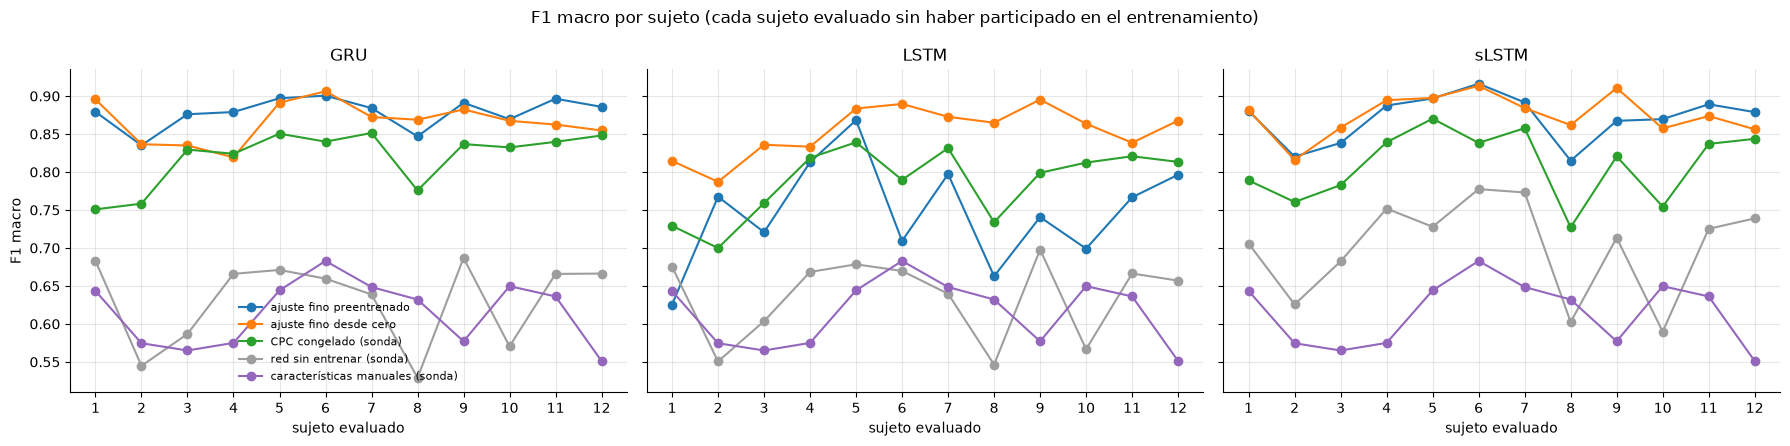

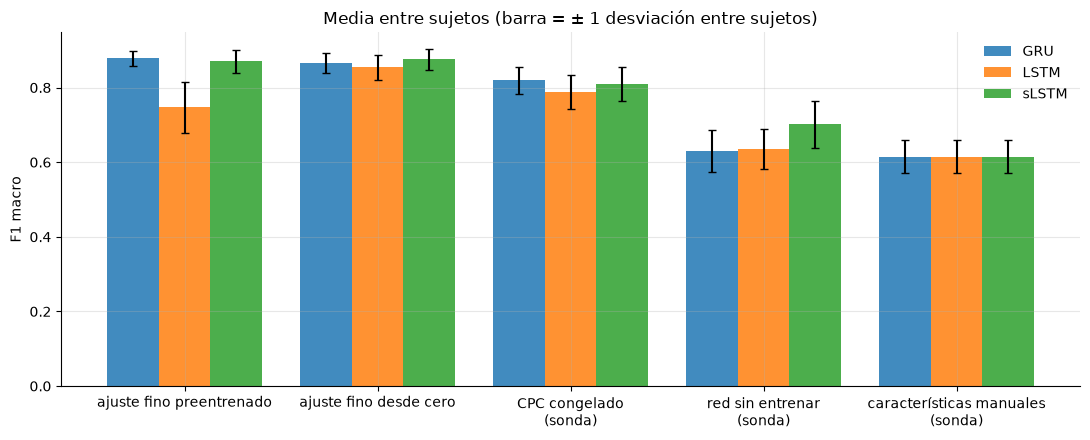

In [24]:
fig, axes = plt.subplots(1, len(DONE_KINDS), figsize=(6 * len(DONE_KINDS), 4.5), sharey=True, squeeze=False)
for ax, k in zip(axes[0], DONE_KINDS):
    for m in METHODS:
        ax.plot(by_subject[k].index, by_subject[k][m], marker="o", label=m, color=METHOD_COLORS[m])
    ax.set(xticks=by_subject[k].index, xlabel="sujeto evaluado", title=k)
axes[0, 0].set_ylabel("F1 macro")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("F1 macro por sujeto (cada sujeto evaluado sin haber participado en el entrenamiento)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
width = 0.8 / len(DONE_KINDS)
for i, k in enumerate(DONE_KINDS):
    pos = np.arange(len(METHODS)) + (i - (len(DONE_KINDS) - 1) / 2) * width
    ax.bar(pos, by_subject[k][METHODS].mean(), width, yerr=by_subject[k][METHODS].std(), capsize=3,
           color=KIND_COLORS[k], label=k, alpha=0.85)
ax.set(xticks=range(len(METHODS)), xticklabels=[m.replace(" (", "\n(") for m in METHODS], ylabel="F1 macro",
       title="Media entre sujetos (barra = ± 1 desviación entre sujetos)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# 10. Comparaciones emparejadas

Cada comparación usa **los mismos sujetos**: para cada persona se resta el F1 de un método menos el del otro. Se reporta:

- la **diferencia media** y su intervalo de confianza del 95 % por *bootstrap* (remuestreando sujetos);
- en **cuántos sujetos** gana el primero;
- el **p-valor de Wilcoxon** (rangos con signo, emparejado; no supone normalidad). Con 12 sujetos, p < 0.05 requiere que la ventaja se repita en la mayoría de las personas.

Hay dos familias de comparaciones: **entre métodos**, dentro de cada `g_ar` (las del 07_LOSO), y **entre `g_ar`**, con el mismo método.

In [25]:
def paired(a, b):
    diff = (a - b).dropna().to_numpy()
    rng = np.random.default_rng(SEED_DATA)
    boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(5000)])
    p = wilcoxon(diff).pvalue if len(diff) >= 5 and np.any(diff != 0) else np.nan
    return {"diferencia media": diff.mean(), "IC 95 %": f"[{np.quantile(boot, .025):+.3f}, {np.quantile(boot, .975):+.3f}]",
            "sujetos en que gana": f"{int((diff > 0).sum())} de {len(diff)}", "p (Wilcoxon)": p}


METHOD_PAIRS = [("ajuste fino preentrenado", "ajuste fino desde cero"),
                ("ajuste fino preentrenado", MANUAL),
                ("ajuste fino desde cero", MANUAL),
                ("CPC congelado (sonda)", "red sin entrenar (sonda)"),
                ("CPC congelado (sonda)", MANUAL)]
rows = [{"g_ar": k, "comparación": f"{a} − {b}", **paired(by_subject[k][a], by_subject[k][b])}
        for k in DONE_KINDS for a, b in METHOD_PAIRS]
print("Entre métodos, dentro de cada g_ar:")
display(pd.DataFrame(rows).set_index(["g_ar", "comparación"]).round({"diferencia media": 3, "p (Wilcoxon)": 4}))

KIND_PAIRS = [(a, b) for i, a in enumerate(DONE_KINDS) for b in DONE_KINDS[i + 1:]]
rows = [{"método": m, "comparación": f"{b} − {a}", "mismo protocolo de ajuste fino": FT_PROTOCOL_BY_KIND[a] == FT_PROTOCOL_BY_KIND[b],
         **paired(by_subject[b][m], by_subject[a][m])}
        for m in NET_METHODS for a, b in KIND_PAIRS]
if rows:
    print("Entre g_ar, con el mismo método:")
    display(pd.DataFrame(rows).set_index(["método", "comparación"]).round({"diferencia media": 3, "p (Wilcoxon)": 4}))

Entre métodos, dentro de cada g_ar:


diferencia media  \
g_ar  comparación                                                            
GRU   ajuste fino preentrenado − ajuste fino desde cero              0.012   
      ajuste fino preentrenado − características manu...             0.263   
      ajuste fino desde cero − características manual...             0.251   
      CPC congelado (sonda) − red sin entrenar (sonda)               0.189   
      CPC congelado (sonda) − características manuale...             0.205   
LSTM  ajuste fino preentrenado − ajuste fino desde cero             -0.107   
      ajuste fino preentrenado − características manu...             0.132   
      ajuste fino desde cero − características manual...             0.239   
      CPC congelado (sonda) − red sin entrenar (sonda)               0.152   
      CPC congelado (sonda) − características manuale...             0.172   
sLSTM ajuste fino preentrenado − ajuste fino desde cero             -0.005   
      ajuste fino preentrenado − características manu...             0.256   
      ajuste fino desde cero − características manual...             0.260   
      CPC congelado (sonda) − red sin entrenar (sonda)               0.109   
      CPC congelado (sonda) − características manuale...             0.195   

                                                                   IC 95 %  \
g_ar  comparación                                                            
GRU   ajuste fino preentrenado − ajuste fino desde cero   [-0.000, +0.026]   
      ajuste fino preentrenado − características manu...  [+0.242, +0.287]   
      ajuste fino desde cero − características manual...  [+0.236, +0.268]   
      CPC congelado (sonda) − red sin entrenar (sonda)    [+0.157, +0.216]   
      CPC congelado (sonda) − características manuale...  [+0.175, +0.234]   
LSTM  ajuste fino preentrenado − ajuste fino desde cero   [-0.144, -0.069]   
      ajuste fino preentrenado − características manu...  [+0.082, +0.179]   
      ajuste fino desde cero − características manual...  [+0.216, +0.265]   
      CPC congelado (sonda) − red sin entrenar (sonda)    [+0.126, +0.178]   
      CPC congelado (sonda) − características manuale...  [+0.141, +0.203]   
sLSTM ajuste fino preentrenado − ajuste fino desde cero   [-0.017, +0.007]   
      ajuste fino preentrenado − características manu...  [+0.235, +0.277]   
      ajuste fino desde cero − características manual...  [+0.239, +0.284]   
      CPC congelado (sonda) − red sin entrenar (sonda)    [+0.094, +0.125]   
      CPC congelado (sonda) − características manuale...  [+0.161, +0.227]   

                                                         sujetos en que gana  \
g_ar  comparación                                                              
GRU   ajuste fino preentrenado − ajuste fino desde cero              8 de 12   
      ajuste fino preentrenado − características manu...            12 de 12   
      ajuste fino desde cero − características manual...            12 de 12   
      CPC congelado (sonda) − red sin entrenar (sonda)              12 de 12   
      CPC congelado (sonda) − características manuale...            12 de 12   
LSTM  ajuste fino preentrenado − ajuste fino desde cero              0 de 12   
      ajuste fino preentrenado − características manu...            11 de 12   
      ajuste fino desde cero − características manual...            12 de 12   
      CPC congelado (sonda) − red sin entrenar (sonda)              12 de 12   
      CPC congelado (sonda) − características manuale...            12 de 12   
sLSTM ajuste fino preentrenado − ajuste fino desde cero              6 de 12   
      ajuste fino preentrenado − características manu...            12 de 12   
      ajuste fino desde cero − características manual...            12 de 12   
      CPC congelado (sonda) − red sin entrenar (sonda)              12 de 12   
      CPC congelado (sonda) − características manuale...            12 de 12   

                                           

Entre g_ar, con el mismo método:


mismo protocolo de ajuste fino  \
método                   comparación                                    
ajuste fino preentrenado LSTM − GRU                              True   
                         sLSTM − GRU                            False   
                         sLSTM − LSTM                           False   
ajuste fino desde cero   LSTM − GRU                              True   
                         sLSTM − GRU                            False   
                         sLSTM − LSTM                           False   
CPC congelado (sonda)    LSTM − GRU                              True   
                         sLSTM − GRU                            False   
                         sLSTM − LSTM                           False   
red sin entrenar (sonda) LSTM − GRU                              True   
                         sLSTM − GRU                            False   
                         sLSTM − LSTM                           False   

                                       diferencia media           IC 95 %  \
método                   comparación                                        
ajuste fino preentrenado LSTM − GRU              -0.131  [-0.166, -0.096]   
                         sLSTM − GRU             -0.007  [-0.017, +0.001]   
                         sLSTM − LSTM             0.124  [+0.090, +0.159]   
ajuste fino desde cero   LSTM − GRU              -0.012  [-0.028, +0.001]   
                         sLSTM − GRU              0.009  [-0.003, +0.025]   
                         sLSTM − LSTM             0.022  [+0.009, +0.036]   
CPC congelado (sonda)    LSTM − GRU              -0.033  [-0.044, -0.022]   
                         sLSTM − GRU             -0.010  [-0.028, +0.007]   
                         sLSTM − LSTM             0.023  [+0.004, +0.038]   
red sin entrenar (sonda) LSTM − GRU               0.004  [-0.000, +0.009]   
                         sLSTM − GRU              0.070  [+0.051, +0.090]   
                         sLSTM − LSTM             0.066  [+0.048, +0.085]   

                                      sujetos en que gana  p (Wilcoxon)  
método                   comparación                                     
ajuste fino preentrenado LSTM − GRU               0 de 12        0.0005  
                         sLSTM − GRU              5 de 12        0.3394  
                         sLSTM − LSTM            12 de 12        0.0005  
ajuste fino desde cero   LSTM − GRU               5 de 12        0.2661  
                         sLSTM − GRU              8 de 12        0.3013  
                         sLSTM − LSTM             9 de 12        0.0068  
CPC congelado (sonda)    LSTM − GRU               0 de 12        0.0005  
                         sLSTM − GRU              5 de 12        0.5186  
                         sLSTM − LSTM            10 de 12        0.0269  
red sin entrenar (sonda) LSTM − GRU               9 de 12        0.1294  
                         sLSTM − GRU             12 de 12        0.0005  
                         sLSTM − LSTM            12 de 12        0.0005

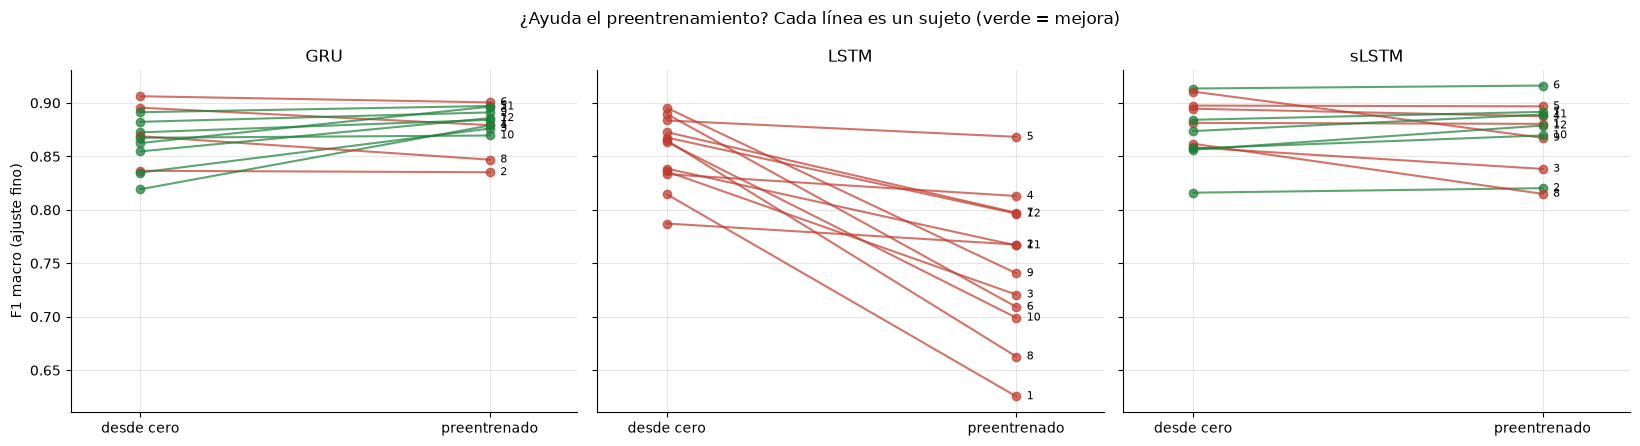

In [26]:
a, b = METHOD_PAIRS[0]
fig, axes = plt.subplots(1, len(DONE_KINDS), figsize=(5.5 * len(DONE_KINDS), 4.5), sharey=True, squeeze=False)
for ax, k in zip(axes[0], DONE_KINDS):
    t = by_subject[k]
    for s in t.index:
        ax.plot([0, 1], [t.loc[s, b], t.loc[s, a]], marker="o",
                color="#1a7f37" if t.loc[s, a] > t.loc[s, b] else "#c0392b", alpha=0.7)
        ax.text(1.03, t.loc[s, a], str(s), va="center", fontsize=8)
    ax.set(xticks=[0, 1], xticklabels=["desde cero", "preentrenado"], xlim=(-0.2, 1.25), title=k)
axes[0, 0].set_ylabel("F1 macro (ajuste fino)")
fig.suptitle("¿Ayuda el preentrenamiento? Cada línea es un sujeto (verde = mejora)")
plt.tight_layout()
plt.show()

### Sensibilidad al horizonte y al protocolo de ajuste fino

Si para un `g_ar` hay otro LOSO **completo** guardado, se compara con el actual sujeto por sujeto, con la misma prueba emparejada:

- **otro protocolo, mismo horizonte:** por ejemplo, el ajuste fino original del 07_LOSO (`<g_ar>/h1s/`) frente a LP-FT (`<g_ar>/h1s_lpft/`). Como el CPC es el mismo, sólo se comparan los dos ajustes finos;
- **otro horizonte:** si el barrido eligió un horizonte distinto de 1 s, el LOSO actual frente al de 1 s.

La segunda tabla cuenta, para cada corrida, en cuántos sujetos el ajuste fino preentrenado queda **por debajo de la sonda sobre el mismo CPC congelado**: es el síntoma de que el ajuste fino deforma la representación (decisión 40).

In [27]:
def run_label(d):
    m = re.fullmatch(r"h([\d.]+)s(?:_(\w+))?", d.name)
    return f"{float(m[1]):g} s · {PROTOCOL_NAMES.get(m[2] or '', m[2])}"


def complete_runs(d):
    rs = [json.loads(p.read_text()) for p in sorted(d.glob("ronda_*.json"))]
    return rs if len(rs) >= len(FOLDS) * len(SEEDS) else None


rows, damage = [], []
for k in DONE_KINDS:
    for d in sorted((RUN_DIR / k).glob("h*s*")):
        rs = complete_runs(d)
        if rs is None:
            continue
        damage.append({"g_ar": k, "corrida": run_label(d), "actual": d == kind_dir(k),
                       "ajuste fino preentrenado": np.mean([r["metrics"]["ajuste fino preentrenado"]["f1_macro"] for r in rs]),
                       "CPC congelado (sonda)": np.mean([r["metrics"]["CPC congelado (sonda)"]["f1_macro"] for r in rs]),
                       "sujetos con ajuste fino < sonda": sum(r["metrics"]["ajuste fino preentrenado"]["f1_macro"]
                                                             < r["metrics"]["CPC congelado (sonda)"]["f1_macro"] for r in rs)})
        if d == kind_dir(k):
            continue
        o = (pd.DataFrame([{"sujeto": r["held_out"], "método": m, "F1": r["metrics"][m]["f1_macro"]} for r in rs for m in NET_METHODS])
             .groupby(["sujeto", "método"])["F1"].mean().unstack())
        same_cpc = d.name.split("_")[0] == kind_dir(k).name.split("_")[0]
        methods = ["ajuste fino preentrenado", "ajuste fino desde cero"] if same_cpc else NET_METHODS
        rows += [{"g_ar": k, "método": m, "comparación": f"{run_label(kind_dir(k))} − {run_label(d)}",
                  **paired(by_subject[k][m], o[m])} for m in methods]
if rows:
    display(pd.DataFrame(rows).set_index(["g_ar", "método", "comparación"]).round({"diferencia media": 3, "p (Wilcoxon)": 4}))
else:
    print("No hay otros LOSO completos con los que comparar.")
print("¿El ajuste fino deforma la representación? (F1 macro medio entre sujetos)")
display(pd.DataFrame(damage).set_index(["g_ar", "corrida"]).round(3))

diferencia media  \
g_ar método                   comparación                                                            
GRU  ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             0.004   
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             0.023   
LSTM ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             0.038   
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             0.106   

                                                                                           IC 95 %  \
g_ar método                   comparación                                                            
GRU  ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...  [-0.003, +0.013]   
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...  [+0.001, +0.055]   
LSTM ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...  [-0.009, +0.085]   
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...  [+0.077, +0.143]   

                                                                                 sujetos en que gana  \
g_ar método                   comparación                                                              
GRU  ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             5 de 12   
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             9 de 12   
LSTM ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...             8 de 12   
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...            12 de 12   

                                                                                  p (Wilcoxon)  
g_ar método                   comparación                                                       
GRU  ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...        0.9097  
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...        0.1099  
LSTM ajuste fino preentrenado 1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...        0.2036  
     ajuste fino desde cero   1 s · LP-FT (30 épocas, paciencia 5) − 1 s · aj...        0.0005

¿El ajuste fino deforma la representación? (F1 macro medio entre sujetos)


actual  \
g_ar  corrida                                                      
GRU   1 s · ajuste fino original (15 épocas, pacienci...   False   
      1 s · LP-FT (30 épocas, paciencia 5)                  True   
LSTM  1 s · ajuste fino original (15 épocas, pacienci...   False   
      1 s · LP-FT (30 épocas, paciencia 5)                  True   
sLSTM 1 s · ajuste fino original (15 épocas, pacienci...    True   

                                                          ajuste fino preentrenado  \
g_ar  corrida                                                                        
GRU   1 s · ajuste fino original (15 épocas, pacienci...                     0.874   
      1 s · LP-FT (30 épocas, paciencia 5)                                   0.878   
LSTM  1 s · ajuste fino original (15 épocas, pacienci...                     0.709   
      1 s · LP-FT (30 épocas, paciencia 5)                                   0.747   
sLSTM 1 s · ajuste fino original (15 épocas, pacienci...                     0.871   

                                                          CPC congelado (sonda)  \
g_ar  corrida                                                                     
GRU   1 s · ajuste fino original (15 épocas, pacienci...                  0.820   
      1 s · LP-FT (30 épocas, paciencia 5)                                0.820   
LSTM  1 s · ajuste fino original (15 épocas, pacienci...                  0.787   
      1 s · LP-FT (30 épocas, paciencia 5)                                0.787   
sLSTM 1 s · ajuste fino original (15 épocas, pacienci...                  0.810   

                                                          sujetos con ajuste fino < sonda  
g_ar  corrida                                                                              
GRU   1 s · ajuste fino original (15 épocas, pacienci...                                0  
      1 s · LP-FT (30 épocas, paciencia 5)                                              0  
LSTM  1 s · ajuste fino original (15 épocas, pacienci...                               10  
      1 s · LP-FT (30 épocas, paciencia 5)                                             10  
sLSTM 1 s · ajuste fino original (15 épocas, pacienci...                                0

# 11. Desempeño por actividad

Se juntan las predicciones de los 12 sujetos evaluados (cada uno predicho por el modelo que no lo vio) y se calcula el F1 por actividad de cada `g_ar` y método, y la matriz de confusión de la mejor combinación.

N     LF      K     PT     LT  \
g_ar  método                                                                
GRU   ajuste fino preentrenado          0.925  0.870  0.902  0.827  0.813   
      ajuste fino desde cero            0.914  0.872  0.899  0.808  0.760   
      CPC congelado (sonda)             0.900  0.828  0.765  0.750  0.732   
      red sin entrenar (sonda)          0.769  0.604  0.645  0.498  0.427   
LSTM  ajuste fino preentrenado          0.865  0.752  0.655  0.687  0.604   
      ajuste fino desde cero            0.927  0.864  0.834  0.791  0.776   
      CPC congelado (sonda)             0.878  0.783  0.733  0.732  0.665   
      red sin entrenar (sonda)          0.772  0.622  0.650  0.503  0.429   
sLSTM ajuste fino preentrenado          0.916  0.872  0.889  0.811  0.805   
      ajuste fino desde cero            0.923  0.878  0.904  0.816  0.797   
      CPC congelado (sonda)             0.872  0.818  0.761  0.752  0.685   
      red sin entrenar (sonda)          0.788  0.651  0.692  0.590  0.505   
—     características manuales (sonda)  0.457  0.660  0.654  0.475  0.368   

                                            W     PF  F1 macro  
g_ar  método                                                    
GRU   ajuste fino preentrenado          0.937  0.902     0.882  
      ajuste fino desde cero            0.934  0.890     0.868  
      CPC congelado (sonda)             0.909  0.885     0.824  
      red sin entrenar (sonda)          0.862  0.619     0.632  
LSTM  ajuste fino preentrenado          0.896  0.795     0.751  
      ajuste fino desde cero            0.925  0.885     0.857  
      CPC congelado (sonda)             0.919  0.828     0.791  
      red sin entrenar (sonda)          0.865  0.620     0.637  
sLSTM ajuste fino preentrenado          0.934  0.898     0.875  
      ajuste fino desde cero            0.934  0.899     0.879  
      CPC congelado (sonda)             0.922  0.885     0.814  
      red sin entrenar (sonda)          0.877  0.826     0.704  
—     características manuales (sonda)  0.882  0.845     0.620

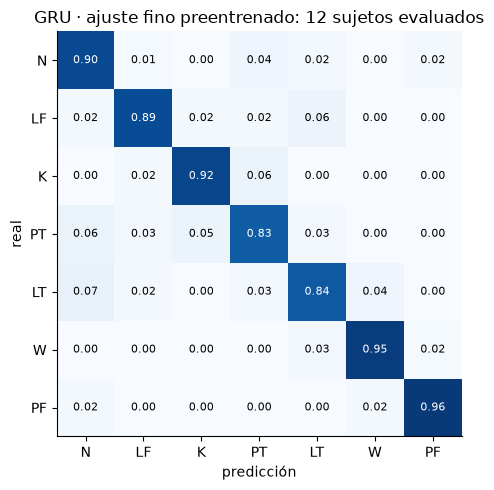

In [28]:
def pooled(rs, method):
    per_seed, cms = [], []
    for seed in sorted({r["seed"] for r in rs}):
        sub = [r for r in rs if r["seed"] == seed]
        y = np.concatenate([r["y"] for r in sub]); p = np.concatenate([r["pred"][method] for r in sub])
        per_seed.append(f1_score(y, p, labels=range(len(LABELS)), average=None, zero_division=0))
        cms.append(confusion_matrix(y, p, labels=range(len(LABELS))))
    cm = np.sum(cms, axis=0)
    return np.mean(per_seed, axis=0), cm / cm.sum(axis=1, keepdims=True)


combos = {(k, m): pooled([r for r in runs if r["config"]["kind"] == k], m) for k in DONE_KINDS for m in NET_METHODS}
combos[("—", MANUAL)] = pooled(list(manual_runs.values()), MANUAL)
per_class = pd.DataFrame({key: v[0] for key, v in combos.items()}, index=LABELS).T
per_class.index.names = ["g_ar", "método"]
per_class["F1 macro"] = per_class.mean(axis=1)
display(per_class.round(3))

best = per_class["F1 macro"].idxmax()
cm = combos[best][1]
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
ax.set(xticks=range(len(LABELS)), xticklabels=LABELS, yticks=range(len(LABELS)), yticklabels=LABELS,
       xlabel="predicción", ylabel="real", title=f"{best[0]} · {best[1]}: {len(manual_runs)} sujetos evaluados")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.55 else "black")
plt.tight_layout()
plt.show()

# 12. ¿Qué tan bien predice CPC la señal?

Las secciones anteriores miden la **clasificación de actividades**. Esta mide la **tarea propia de CPC**: dado el contexto `c_t`, reconocer el futuro real de la señal (`z_{t+k}`) entre 128 candidatos, para cada `g_ar`.

Para cada modelo guardado:

- se usa el **sujeto evaluado** de esa ronda, que el modelo nunca vio, con el escalador de la ronda;
- se forman 40 lotes de 128 recortes aleatorios de ese sujeto (todos los candidatos son de **la misma persona**, como en el entrenamiento);
- se mide la **accuracy contrastiva** y la pérdida InfoNCE por horizonte `k`;
- se repite con **la red sin entrenar guardada** (los mismos pesos iniciales) como referencia.

El **azar** es 1/128 ≈ 0.8 % de accuracy y una pérdida de log(128) ≈ 4.85.

Tarea de CPC en el sujeto evaluado (media y desviación entre rondas):


pérdida        accuracy       
                          mean    std     mean    std
g_ar  modelo                                         
GRU   CPC                2.322  0.474    0.353  0.123
      red sin entrenar   4.852  0.000    0.008  0.000
LSTM  CPC                2.084  0.436    0.415  0.100
      red sin entrenar   4.852  0.000    0.008  0.000
sLSTM CPC                2.342  0.481    0.347  0.129
      red sin entrenar   4.856  0.001    0.008  0.000
—     azar               4.852  0.000    0.008  0.000

Accuracy por horizonte de predicción (CPC):


,83 ms,167 ms,250 ms,333 ms,417 ms,500 ms,583 ms,667 ms,750 ms,833 ms,917 ms,1000 ms
g_ar,,,,,,,,,,,,
GRU,0.553,0.512,0.461,0.411,0.373,0.341,0.314,0.290,0.270,0.251,0.235,0.222
LSTM,0.618,0.573,0.522,0.477,0.438,0.405,0.379,0.355,0.334,0.313,0.292,0.278
sLSTM,0.528,0.485,0.443,0.398,0.366,0.340,0.314,0.290,0.273,0.255,0.242,0.227


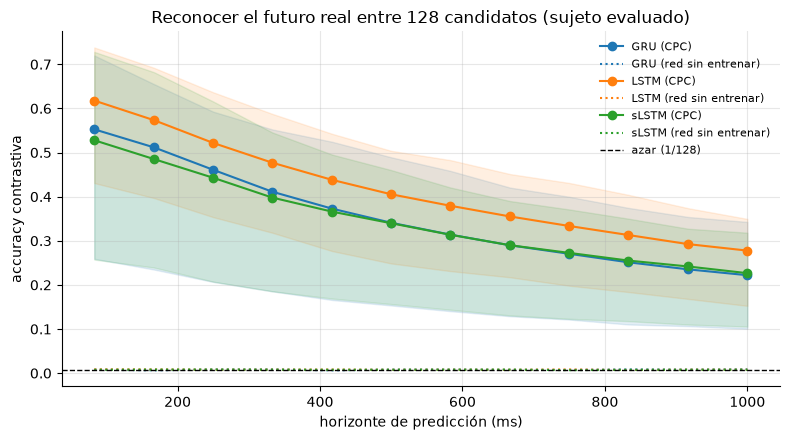

In [29]:
B_EVAL, N_BATCH_EVAL = 128, 40
rows = []
for kind in DONE_KINDS:
    for path in sorted(kind_dir(kind).glob("ronda_*.pt")):
        if not path.with_suffix(".json").exists():
            continue
        ckpt = torch.load(path, map_location=DEVICE)
        r = json.loads(path.with_suffix(".json").read_text())
        set_series(apply_scaler(ckpt["scaler"]))
        pool = CPCBatchSampler((r["held_out"],), "mezclado", 0).starts      # todos los inicios válidos del sujeto evaluado
        for name, key in (("CPC", "cpc"), ("red sin entrenar", "red sin entrenar")):
            model = build_model(kind, r["seed"], r["config"]["horizons"])
            model.load_state_dict(ckpt[key])
            model.eval()
            g = np.random.default_rng(123)
            lo, hi = model.anchor_range(WIN)
            losses, accs = [], []
            with torch.no_grad():
                for _ in range(N_BATCH_EVAL):
                    x = get_windows(g.choice(pool, B_EVAL, replace=False))
                    anchors = g.integers(lo, hi, size=model.cfg.n_anchors).tolist()
                    _, loss_k, acc_k = model.info_nce(x, anchors=anchors)
                    losses.append(loss_k.cpu().numpy())
                    accs.append(acc_k.cpu().numpy())
            acc_k, loss_k = np.mean(accs, axis=0), np.mean(losses, axis=0)
            rows.append({"g_ar": kind, "sujeto": r["held_out"], "semilla": r["seed"], "modelo": name,
                         "pérdida": loss_k.mean(), "accuracy": acc_k.mean(),
                         **{f"{1000 * k / TARGET_FS:.0f} ms": a for k, a in zip(r["config"]["horizons"], acc_k)}})
            del model
cpc_task = pd.DataFrame(rows)
horizon_cols = sorted([c for c in cpc_task.columns if c.endswith(" ms")], key=lambda c: int(c.split()[0]))   # cada g_ar tiene sus horizontes

summary_task = cpc_task.groupby(["g_ar", "modelo"])[["pérdida", "accuracy"]].agg(["mean", "std"]).reindex(DONE_KINDS, level=0)
summary_task.loc[("—", "azar"), :] = [math.log(B_EVAL), 0.0, 1 / B_EVAL, 0.0]
print("Tarea de CPC en el sujeto evaluado (media y desviación entre rondas):")
display(summary_task.round(3))
print("Accuracy por horizonte de predicción (CPC):")
display(cpc_task[cpc_task["modelo"] == "CPC"].groupby("g_ar")[horizon_cols].mean().reindex(DONE_KINDS).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for k in DONE_KINDS:
    for name, ls, marker in (("CPC", "-", "o"), ("red sin entrenar", ":", None)):
        sub = cpc_task[(cpc_task["g_ar"] == k) & (cpc_task["modelo"] == name)][horizon_cols].dropna(axis=1, how="all")
        ms = [int(c.split()[0]) for c in sub.columns]
        ax.plot(ms, sub.mean(), ls=ls, marker=marker, color=KIND_COLORS[k], label=f"{k} ({name})")
        if name == "CPC":
            ax.fill_between(ms, sub.quantile(0.1), sub.quantile(0.9), color=KIND_COLORS[k], alpha=0.12)
ax.axhline(1 / B_EVAL, color="black", ls="--", lw=1, label="azar (1/128)")
ax.set(xlabel="horizonte de predicción (ms)", ylabel="accuracy contrastiva",
       title="Reconocer el futuro real entre 128 candidatos (sujeto evaluado)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

# 13. Costo de entrenamiento

Minutos por ronda y épocas elegidas por la parada temprana, en promedio sobre las rondas terminadas. Sirve para decidir si una diferencia de F1 entre `g_ar` justifica su costo.

In [30]:
cost = pd.DataFrame([{"g_ar": r["config"]["kind"], "min por ronda": r["minutes"],
                      "min CPC": r["info"]["cpc"]["minutes"], "época CPC elegida": r["info"]["cpc"]["best_epoch"],
                      "min ajuste fino preentrenado": r["info"]["ajuste fino preentrenado"]["minutes"],
                      "época ajuste fino preentrenado": r["info"]["ajuste fino preentrenado"]["best_epoch"],
                      "min ajuste fino desde cero": r["info"]["ajuste fino desde cero"]["minutes"],
                      "época ajuste fino desde cero": r["info"]["ajuste fino desde cero"]["best_epoch"]} for r in runs])
table = cost.groupby("g_ar").mean().reindex(DONE_KINDS)
table.insert(0, "parámetros g_ar", timing["parámetros g_ar"].reindex(DONE_KINDS))
table.insert(0, "horizonte (s)", [HORIZON_S_BY_KIND[k] for k in DONE_KINDS])
table.insert(0, "ajuste fino", [PROTOCOL_NAMES[FT_PROTOCOL_BY_KIND[k]] for k in DONE_KINDS])
table["horas (todas las rondas)"] = cost.groupby("g_ar")["min por ronda"].sum().reindex(DONE_KINDS) / 60
display(table.round(1))

,ajuste fino,horizonte (s),parámetros g_ar,min por ronda,min CPC,época CPC elegida,min ajuste fino preentrenado,época ajuste fino preentrenado,min ajuste fino desde cero,época ajuste fino desde cero,horas (todas las rondas)
g_ar,,,,,,,,,,,
GRU,"LP-FT (30 épocas, paciencia 5)",1.0,691200,7.3,1.8,9.5,3.2,11.9,4.1,16.9,1.5
LSTM,"LP-FT (30 épocas, paciencia 5)",1.0,921600,5.4,1.5,11.2,1.4,4.2,3.9,23.7,1.1
sLSTM,"ajuste fino original (15 épocas, paciencia 3)",1.0,1219668,24.0,4.2,6.0,9.5,8.4,10.1,9.1,4.8


# 14. Cómo recargar los modelos guardados

`load_saved` reconstruye, **sin entrenar**, todo lo de una ronda: el CPC preentrenado, la red sin entrenar, los dos ajustes finos, las tres sondas, el escalador y el resultado. Cada modelo se reconstruye con los horizontes guardados en su configuración. Para usarlos con ventanas nuevas hay que escalar la serie con el escalador de esa ronda (`set_series(apply_scaler(saved["scaler"]))`).

La celda lo comprueba: vuelve a predecir el sujeto evaluado de la primera ronda guardada de cada `g_ar` y compara con las predicciones guardadas. En MPS o CUDA puede haber diferencias mínimas por el redondeo de punto flotante.

In [31]:
def load_saved(kind, held_out, seed=0):
    """Redes, sondas, escalador y resultado guardados de una ronda (sin volver a entrenar)."""
    path = kind_dir(kind) / f"ronda_s{held_out:02d}_semilla{seed}"
    ckpt = torch.load(path.with_suffix(".pt"), map_location=DEVICE)
    models = {}
    for key in ("cpc", "red sin entrenar"):
        models[key] = build_model(kind, seed, ckpt["config"]["horizons"])
        models[key].load_state_dict(ckpt[key])
        models[key].eval()
    for key in ("ajuste fino preentrenado", "ajuste fino desde cero"):
        models[key] = CPCClassifier(build_model(kind, seed, ckpt["config"]["horizons"])).to(DEVICE)
        models[key].load_state_dict(ckpt[key])
        models[key].eval()
    probes = joblib.load(path.with_suffix(".joblib"))
    probes[MANUAL] = joblib.load(MANUAL_DIR / f"ronda_s{held_out:02d}.joblib")
    return {"models": models, "probes": probes, "scaler": ckpt["scaler"], "config": ckpt["config"],
            "result": json.loads(path.with_suffix(".json").read_text())}


rows = []
for kind in DONE_KINDS:
    r = next(r for r in runs if r["config"]["kind"] == kind)
    saved = load_saved(kind, r["held_out"], r["seed"])
    set_series(apply_scaler(saved["scaler"]))
    held = sup_cv.loc[saved["result"]["index"]]
    starts, m, p = starts_of(held), saved["models"], saved["probes"]
    again = {"ajuste fino preentrenado": predict(m["ajuste fino preentrenado"], starts),
             "ajuste fino desde cero": predict(m["ajuste fino desde cero"], starts),
             "CPC congelado (sonda)": p["CPC congelado (sonda)"].predict(extract(m["cpc"], starts)),
             "red sin entrenar (sonda)": p["red sin entrenar (sonda)"].predict(extract(m["red sin entrenar"], starts)),
             MANUAL: p[MANUAL].predict(features.loc[held.index, FEATURE_COLUMNS].to_numpy(np.float32))}
    stored = {**saved["result"]["pred"], MANUAL: manual_runs[r["held_out"]]["pred"][MANUAL]}
    rows.append({"g_ar": kind, "sujeto": r["held_out"],
                 **{meth: float(np.mean(again[meth] == np.asarray(stored[meth]))) for meth in METHODS}})
print("Fracción de ventanas con la misma predicción que la guardada:")
display(pd.DataFrame(rows).set_index(["g_ar", "sujeto"]).round(4))

Fracción de ventanas con la misma predicción que la guardada:


,,ajuste fino preentrenado,ajuste fino desde cero,CPC congelado (sonda),red sin entrenar (sonda),características manuales (sonda)
g_ar,sujeto,,,,,
GRU,1,1.0,1.0,1.0,1.0,1.0
LSTM,1,1.0,1.0,1.0,1.0,1.0
sLSTM,1,1.0,1.0,1.0,1.0,1.0


# 15. Cómo leer los resultados

- **Desempeño esperado en una persona nueva:** la tabla resumen de la sección 9. La desviación entre sujetos dice cuánto puede variar de una persona a otra; el mínimo, qué tan mal puede ir en el peor caso.
- **¿Ayuda el preentrenamiento?** Primera comparación de la sección 10, para cada `g_ar`. Se considera establecido si el intervalo de confianza no incluye el 0, la ventaja aparece en la mayoría de los sujetos y p < 0.05. Si no, la conclusión honesta es que preentrenar y entrenar desde cero rinden igual con estos datos.
- **¿Supera a las características manuales?** Segunda y tercera comparaciones. Con MVNX, la media de cada variable en la ventana ya describe bien la postura; si los modelos no la superan en la mayoría de los sujetos, la dinámica temporal que aprenden no agrega información para clasificar.
- **¿Qué aprende CPC por sí solo?** Cuarta comparación: CPC congelado contra la misma red sin entrenar, con el mismo clasificador lineal. La sección 12 muestra si CPC aprendió su propia tarea, aunque eso no garantiza que ayude a clasificar (ver la sección 10 del 07_LOSO).
- **¿Qué `g_ar` conviene?** Comparaciones entre `g_ar` de la sección 10, junto con el costo de la sección 12. Si las diferencias no son consistentes entre sujetos, conviene el `g_ar` más barato.
- **¿Ayudó LP-FT?** La sección 10 compara LP-FT con el ajuste fino original con el mismo CPC, y cuenta en cuántos sujetos el ajuste fino queda por debajo de la sonda congelada. Antes de ejecutar se esperaba que la LSTM dejara de quedar por debajo y que la GRU (control) casi no cambiara; la GRU se comportó así, pero la LSTM no (sección 17). La sLSTM no se reentrenó con LP-FT (decisión 47).
- **¿Qué horizonte?** Sólo si se activa el barrido: la sección 7 muestra qué tan sensible es cada `g_ar` al horizonte. Si las diferencias entre horizontes son menores que la variación entre semillas, la elección casi no importa.
- **Siguiente paso:** con la metodología y el `g_ar` elegidos, entrenar el modelo final con los 12 sujetos y **abrir la prueba (13–14) una sola vez**.

# 16. Decisiones de diseño y su justificación

Resumen de las decisiones tomadas en conjunto al diseñar este notebook y la razón técnica de cada una.

## Datos y entrada

| # | Decisión | Justificación técnica |
|---|---|---|
| 1 | **Entrada: sólo MVNX**, sin ningún dato de la sEMG (ni señal ni etiquetas) | El 08 y el 09 mostraron que la información que separa las actividades está en el movimiento. Usar una sola modalidad aísla la comparación entre metodologías y `g_ar`: cualquier diferencia se debe al método, no a la mezcla de fuentes |
| 2 | **Las 30 variables derivadas del 08/09**, no las 782 columnas del MVNX | Con 10 sujetos de entrenamiento por ronda, 782 columnas muy redundantes (posiciones, velocidades y aceleraciones de los mismos segmentos, cuaterniones, columnas con NaN) favorecen el sobreajuste a las personas del entrenamiento. Las 30 resumen postura, alcance, velocidad y apoyo con una variable por concepto |
| 3 | **Etiqueta `label_mvnx`** del instante final de la ventana | Es la etiqueta anotada sobre el propio MVNX. Mantiene la regla `final_instant` del Avance 2 (la ventana describe lo que pasa al final) y elimina la dependencia de la sEMG |
| 4 | **Un ensayo por archivo MVNX**; los bimanuales ya no se parten en dos | En el 09 cada ensayo bimanual aparecía dos veces con el mismo MVNX, lo que duplicaba su peso en el entrenamiento y en la evaluación. Sin sEMG no hay razón para partirlo |
| 5 | **Lados fijos** (`izq_*` / `der_*`) en lugar de ipsi/contra | El orden ipsi/contra del 08/09 se definía respecto al brazo con sEMG. El MVNX mide siempre los dos lados del cuerpo, así que la variable `izq_codo_flexion` significa lo mismo en todos los ensayos. Costo: un levantamiento con la mano izquierda y otro con la derecha se ven distintos en las columnas, y el modelo debe aprender que son la misma actividad |
| 6 | **Variables invariantes a la posición y al rumbo** dentro del laboratorio | Ninguna variable usa `x, y` absolutas. Las alturas usan sólo `z` (respecto al piso); el alcance es la distancia horizontal mano–pelvis; las velocidades y los giros se resumen con magnitudes, que no dependen de hacia dónde mira la persona; los ángulos articulares ya son relativos al cuerpo. Así, la misma actividad da los mismos valores en cualquier punto de la sala |
| 7 | **Rapidez de la mano en el marco del laboratorio** (no relativa a la pelvis) | Se mantiene igual que en el 08/09 para que las variables sean las mismas. Incluye el desplazamiento del cuerpo cuando la persona camina, lo que también es informativo para actividades como W |
| 8 | **Escalador por ronda** con los 10 sujetos de entrenamiento: `clip` (q0.1 %, q99.9 %) y `(x − mediana) / (q95 − q5)`; contactos 0/1 sin cambio | Ajustarlo con los sujetos evaluados filtraría información. La mediana y el rango entre percentiles son robustos a las colas largas de velocidades y giros; el `log1p` de la sEMG no sirve para ángulos ni velocidades con signo |
| 9 | **Ventanas de 48 pasos (4 s)**, una ventana CPC cada 24 pasos y una supervisada cada 6 | Las mismas reglas del Avance 2 y del 08/09, para que los resultados sean comparables. Se escriben en el código en lugar de leerlas de la exportación del Avance 2, para no depender de los archivos de sEMG |

## Modelos

| # | Decisión | Justificación técnica |
|---|---|---|
| 10 | **Tres `g_ar`: GRU, LSTM y sLSTM** | Son tres celdas recurrentes con la misma interfaz `z → c`, así la comparación responde a una pregunta concreta: ¿importa el tipo de celda recurrente? La GRU es la del artículo de referencia (Haresamudram et al., 2020); la LSTM agrega una compuerta de salida y un estado de celda separado; la sLSTM agrega la compuerta de entrada exponencial y el normalizador de xLSTM |
| 11 | **sLSTM como representante de xLSTM** (no mLSTM ni bloques mezclados) | La sLSTM fue la ganadora del 06 y la que usaron el 07–09. Además es recurrente, como GRU y LSTM. La mLSTM procesa la ventana en paralelo con una matriz T × T (una familia más cercana a la atención) y quedó por debajo en el 06; los bloques mezclados nunca se validaron en el proyecto |
| 12 | **LSTM nueva con `nn.LSTM`**, 2 capas de 256 unidades y dropout 0.2 entre capas | El mismo tamaño y la misma regularización que la GRU, para que la diferencia sea sólo la celda. Se usa la implementación de PyTorch, que es estándar y causal |
| 13 | **Configuración idéntica para los tres `g_ar`**, salvo el horizonte de CPC: negativos del mismo sujeto, `c_T`, mismos LR, épocas y paciencia | Si sólo cambian la celda y su horizonte, la diferencia de F1 se les puede atribuir. El horizonte se elige para cada `g_ar` (decisiones 33–39; desactivado en esta ejecución, decisión 46); el resto viene del 06, elegido con sEMG y sLSTM |
| 14 | **Mismo encoder inicial** para los tres `g_ar` con la misma semilla (se verifica en la sección 5) | Elimina una fuente de variación: los tres modelos parten del mismo `g_enc` y sólo difieren en el `g_ar` |

## Metodologías y protocolo

| # | Decisión | Justificación técnica |
|---|---|---|
| 15 | **Las cinco metodologías del 07_LOSO** en cada ronda y para cada `g_ar` | Separan los efectos: el ajuste fino preentrenado frente al desde cero mide el aporte del preentrenamiento; CPC congelado frente a la red sin entrenar mide lo que aprende CPC por sí solo; las características manuales son la referencia clásica sin aprendizaje de representaciones |
| 16 | **Características manuales: la media de cada una de las 30 variables** en la ventana (30 características) | Es la referencia más simple posible con la misma información de entrada que los modelos. Si una red no supera a la postura promedio de la ventana, su modelado temporal no está aportando. Para los contactos de los pies, la media es la fracción de la ventana con el pie apoyado |
| 17 | Medias calculadas sobre la **serie sin escalar** | La sonda tiene su propio `StandardScaler`, y la media es lineal: escalar antes o después da la misma información, salvo el `clip` de valores extremos. Así no dependen del escalador de cada ronda |
| 18 | **Sonda manual una vez por ronda**, común a los tres `g_ar` | No depende del `g_ar` ni de la semilla: la muestra de entrenamiento de la sonda es la misma (`random_state` fijo) y la regresión logística con `lbfgs` es determinista. Repetirla daría el mismo resultado tres veces |
| 19 | **LOSO con los sujetos 1–12**: en cada ronda, un sujeto se evalúa, el siguiente decide la parada temprana y 10 entrenan; **13 y 14 cerrados** | Mide la generalización a una persona nueva 12 veces. La parada temprana no puede mirar al sujeto evaluado. La prueba final se abre una sola vez, con la metodología ya elegida |
| 20 | **Sólo la semilla 0** | La misma semilla del 08/09 y la mitad del tiempo de cómputo. Limitación: no hay estimación de la variación entre semillas; en el 07 fue menor que la variación entre sujetos |
| 21 | **Orden por modelo: GRU → LSTM → sLSTM**, cada uno con sus 12 rondas | Con LP-FT, GRU y LSTM tardan ≈ 8 min por ronda y la sLSTM ≈ 36 min (sección 5). Así, dos de los tres modelos tienen resultados completos en las primeras ≈ 3.5 h del LOSO; si la ejecución se interrumpe, se pierde a lo sumo una ronda |

## Resultados y almacenamiento

| # | Decisión | Justificación técnica |
|---|---|---|
| 22 | **Se guardan los pesos de todas las redes**: CPC preentrenado, red sin entrenar y los dos ajustes finos (`.pt`) | Permite reevaluar, analizar o usar cualquier modelo sin reentrenar (sección 14). La red sin entrenar se podría reconstruir con la semilla, pero se guarda porque la inicialización puede cambiar entre versiones de PyTorch |
| 23 | **Se guardan las tres sondas lineales** (`.joblib`) | Las sondas forman parte de tres metodologías; sin ellas habría que volver a extraer representaciones y reajustar para reproducir las predicciones |
| 24 | **No se guardan las representaciones extraídas** | Ocuparían ≈ 30–60 MB por ronda y modelo, y se recalculan en segundos a partir de los pesos guardados |
| 25 | **El `.json` de cada ronda se escribe al final**, después de los pesos y las sondas | Sirve como marca de ronda completa: si existe, todo lo demás también; si la ejecución se interrumpe, esa ronda se repite desde el principio |
| 26 | **Comparaciones sólo dentro del notebook 10** | Los resultados del 07–09 no están en esta máquina y, además, usan otra etiqueta (sEMG) y otros ensayos (bimanuales partidos en dos), así que no se podrían comparar ventana por ventana |

## Ensayos recuperados

| # | Decisión | Justificación técnica |
|---|---|---|
| 27 | **Incluir los 3 ensayos que el 07_Sincronizacion excluyó sólo por la sEMG** (`Subj_07_MMH_Bim_08kg_Trial_3`, `Subj_07_MMH_Bim_12kg_Trial_1`, `Subj_07_MMH_Bim_12kg_Trial_2`) | Se excluyeron porque la sEMG del brazo derecho tenía canales rotos (desviación estándar cruda > 50 mV). Ese problema no afecta al MVNX, y como la sEMG no se usa, el motivo de exclusión ya no aplica. Los otros 9 excluidos tienen problemas en el propio MVNX (saltos de tiempo o etiquetas inconsistentes) y siguen fuera |
| 28 | **Leerlos del MVNX crudo** con el mismo procedimiento que el 07_Sincronizacion, en lugar de regenerar toda su exportación | El 07_Sincronizacion los descartó antes de procesarlos, así que no están en su caché. Regenerar la exportación cambiaría los datos de los notebooks 08 y 09; leer sólo estos 3 deja intacto lo demás |
| 29 | **Verificar la reimplementación** contra la exportación en un ensayo incluido del mismo sujeto y tipo (`Subj_07_MMH_Bim_08kg_Trial_1`) | Con la misma rejilla de tiempos, la reimplementación reproduce la exportación (diferencia máxima 0 y etiquetas idénticas), así que los ensayos recuperados se procesan igual que los demás |
| 30 | **Exigir los mismos controles de MVNX**: sin saltos de tiempo, etiquetas MVNX consistentes y sin NaN | Son los criterios que el 07_Sincronizacion aplica al MVNX; los tres ensayos los pasan (sección 2.1) |
| 31 | **Rejilla sobre toda la grabación MVNX** en los ensayos recuperados | Sin sEMG no hay otra señal con la cual traslapar. En los demás ensayos, la rejilla se recortó al tramo con sEMG; en una muestra de 8 ensayos, el recorte fue de 0–3 s en siete y de 24 s en uno. Los extremos de una grabación suelen ser reposo o tramos sin etiqueta, así que incluirlos en los recuperados no cambia qué se evalúa |
| 32 | `validacion_dudosa = False` en los recuperados | Esa marca evalúa la alineación sEMG–MVNX, que no existe para estos ensayos; no describe la calidad del MVNX |

Los tres ensayos son del **sujeto 7**, que está en la validación cruzada: entran al entrenamiento en 10 rondas, a la validación interna en la ronda 6 y a la evaluación en la ronda 7.

## Barrido del horizonte

| # | Decisión | Justificación técnica |
|---|---|---|
| 33 | **Elegir el horizonte de CPC para cada `g_ar` con MVNX** antes del LOSO | La configuración del 06 se eligió con sEMG y sLSTM. El horizonte es el parámetro más ligado a la señal: define qué tan lejos en el futuro debe predecir CPC, y la escala temporal del movimiento no es la de la envolvente sEMG. Además, cada celda recurrente puede aprovechar horizontes distintos |
| 34 | **Sólo se barre el horizonte**: 0.5, 1 y 2 s | 0.5 y 1 s son los del 06; 2 s explora dinámicas más lentas (el ciclo de una tarea MMH dura varios segundos) y es el máximo que cabe en la ventana de 4 s sin dejar casi sin anclajes. Barrer más parámetros multiplicaría el costo y el riesgo de sobreajustar la selección a dos sujetos |
| 35 | **Selección con los sujetos 11–12**, entrenando con 1–10 | La misma división del 06. Los sujetos 13 y 14 siguen cerrados |
| 36 | **Criterio: F1 macro de la sonda lineal sobre CPC congelado** (`c_T`) | El criterio del 06 y el mismo que usa la parada temprana de CPC. Es barato (no requiere ajuste fino por configuración) y mide directamente la calidad de la representación que produce cada horizonte. Limitación: optimiza la representación congelada, no el ajuste fino |
| 37 | **Dos etapas**: todo con la semilla 0; los 2 mejores horizontes de cada `g_ar`, con las semillas 0, 1 y 2 | Con una semilla, diferencias de ±0.02–0.03 pueden ser ruido de la inicialización. Elegir por la media de tres semillas reduce ese riesgo sin repetir todas las combinaciones |
| 38 | **El LOSO lee el horizonte elegido** (`HORIZON_S_BY_KIND`, guardado en `barrido/seleccion.json`); cada horizonte y protocolo de ajuste fino tiene su carpeta (`<g_ar>/h<horizonte>s[_lpft]/`) y cada ronda guarda ambos | Evita copiar valores a mano y mezclar configuraciones: rondas con horizontes distintos nunca comparten carpeta, y si una ronda guardada no coincide con el horizonte elegido, el notebook se detiene |
| 39 | **Conservar el LOSO que ya se corrió con 1 s** (antes de agregar el barrido y LP-FT) en `<g_ar>/h1s/` | Se entrenó con la configuración del 06 y el ajuste fino original (7.1 h), con los mismos datos, incluidos los ensayos recuperados. Sirve como comparación emparejada (sección 10) y sus CPC se reutilizan cuando el barrido elige 1 s (decisión 44) |

## Protocolo de ajuste fino: LP-FT (decidido después de la corrida con 1 s)

Estas decisiones se tomaron **después** de ver la corrida con el ajuste fino original (`<g_ar>/h1s/`). Para que no sea un ajuste a los sujetos evaluados: el diagnóstico se apoya en la **validación interna**, la corrección es una técnica publicada elegida de antemano, se aplica **una sola vez** e igual a los dos ajustes finos de cada `g_ar` en que se usa, y las dos versiones se reportan.

| # | Decisión | Justificación técnica |
|---|---|---|
| 40 | **LP-FT** (*linear probing, then fine-tuning*; Kumar et al., 2022, ICLR): primero se entrena sólo la cabeza con el encoder y el `g_ar` congelados; después se ajusta todo, partiendo de esa cabeza | Con una cabeza al azar, los primeros gradientes son grandes y sin dirección útil, y **deforman la representación preentrenada** antes de que la cabeza aprenda a usarla. El artículo muestra que el daño es mayor fuera de la distribución de entrenamiento, que es el caso de LOSO (cada evaluación es una persona nueva). En la corrida original, la LSTM mostraba el síntoma **ya en la validación interna**: su ajuste fino arrancaba con F1 de 0.25–0.6 en 8 de 12 rondas (mediana 0.58), y su mejor época quedó por debajo de la sonda sobre su CPC congelado en **12 de 12** rondas (0.741 frente a 0.822). GRU (1 de 12) y sLSTM (0 de 12) no lo mostraban. En los sujetos evaluados se repitió: 10 de 12 (0.709 frente a 0.787) |
| 41 | **Hasta 30 épocas con paciencia 5** (antes, 15 y 3) | En la validación interna, varias rondas seguían mejorando al llegar al límite de 15 épocas: 28 de los 72 ajustes finos lo agotaron, sobre todo los desde cero (la LSTM, en 9 de 12). La paciencia de 3 cortaba curvas ruidosas que aún subían |
| 42 | **LP-FT también en el ajuste fino desde cero** | Los dos ajustes finos deben seguir el mismo protocolo para que su diferencia mida sólo el preentrenamiento. Desde cero, la etapa LP entrena la cabeza sobre la red sin entrenar |
| 43 | **La cabeza de LP (época 0) es candidata en la parada temprana**, y la etapa LP tiene su propia parada temprana (hasta 20 épocas, paciencia 3, LR 1e-3) | Si ajustar toda la red no mejora la validación interna, se conserva la cabeza de LP sobre la representación sin tocar: el ajuste fino no puede quedar por debajo de LP en validación. Todo se decide con el sujeto de validación interna, nunca con el evaluado |
| 44 | **Reutilizar el CPC** de la corrida original cuando coinciden ronda, `g_ar`, horizonte y semilla | El preentrenamiento no depende del protocolo de ajuste fino; reutilizarlo ahorra tiempo y hace que la comparación entre protocolos sea exacta (mismo CPC, sólo cambia el ajuste fino). Se verifica que el escalador de la ronda coincida |
| 45 | **Conservar y reportar las dos versiones** (sección 10) | Reportar ambas evita elegir a posteriori la que mejor salga. El alcance de LP-FT (qué `g_ar` lo usan) se acotó por costo en las decisiones 46–48 |

## Alcance de esta ejecución (opción de menor costo)

Con LP-FT en los tres `g_ar` y el barrido, la ejecución tomaba ≈ 11–12 h; ≈ 7 h correspondían a la sLSTM, el `g_ar` en que menos se esperaba cambio. Se eligió una ejecución acotada (≈ 3 h) que responde la pregunta principal.

| # | Decisión | Justificación técnica |
|---|---|---|
| 46 | **No ejecutar el barrido del horizonte** (`RUN_SWEEP = False`): horizonte fijo de 1 s | En las corridas que alcanzó a hacer, las diferencias entre horizontes fueron del orden del ruido (GRU: 0.835, 0.852 y 0.856 con 0.5, 1 y 2 s; LSTM con 0.5 s: 0.810, frente a 0.835 con 1 s, en los sujetos 11–12, una semilla). Su efecto esperado sobre el ajuste fino es pequeño, cuesta ≈ 1 h y, si elegía otro horizonte, obligaba a reentrenar CPC. El código queda listo para ejecutarse |
| 47 | **LP-FT sólo en GRU y LSTM**; la sLSTM conserva el ajuste fino original (`sLSTM/h1s/`) | La **LSTM** es la que muestra el síntoma (12 de 12 rondas en validación interna). La **GRU** sirve de **control**: tampoco tiene el síntoma (1 de 12), así que si LP-FT no la cambia, la mejora de la LSTM se atribuye a corregir el problema y no a un protocolo que infla cualquier resultado. La **sLSTM** no tiene el síntoma (0 de 12) y representa ≈ 70 % del costo |
| 48 | Las comparaciones entre `g_ar` que incluyen a la sLSTM **mezclan protocolos**, y se señalan | La columna "mismo protocolo de ajuste fino" de la sección 10 lo indica. La comparación limpia es GRU frente a LSTM (ambas con LP-FT); para la sLSTM, la comparación limpia es con el ajuste fino original de GRU y LSTM (`<g_ar>/h1s/`). Si se necesita la comparación completa, basta poner `FT_PROTOCOL_BY_KIND["sLSTM"] = "lpft"` y volver a ejecutar (≈ 7 h, con el CPC reutilizado) |

## Limitaciones conocidas

- En los ensayos de la exportación, el inicio y el fin de la rejilla se recortaron al tramo con sEMG (herencia del 07_Sincronizacion). Ningún valor de sEMG entra al modelo, pero la duración de esos ensayos sí dependió de ella; quitarlo requiere reprocesar todos los MVNX crudos.
- El horizonte de 1 s y el resto de la configuración (negativos, `c_T`, LR) vienen del 06, elegidos con sEMG y sLSTM; el barrido con MVNX está implementado pero no se ejecutó (decisión 46). Si se activa, los sujetos 11 y 12 quedan algo optimistas en el LOSO, porque eligen el horizonte.
- La sLSTM usa otro protocolo de ajuste fino que GRU y LSTM (decisiones 47–48): las comparaciones de la sLSTM con ellas mezclan el efecto de la celda con el del protocolo.
- LP-FT y las 30 épocas se decidieron después de ver una corrida LOSO completa (decisiones 40–45). El diagnóstico se apoya en la validación interna y el cambio no se ajustó a los sujetos evaluados, pero el notebook ya no es un protocolo fijado por completo de antemano; la prueba final con los sujetos 13 y 14 sigue siendo la evaluación sin sesgo.
- Con una sola semilla (decisión 20), las diferencias pequeñas entre `g_ar` deben leerse con cautela aunque sean consistentes entre sujetos.

# 17. Conclusiones

*Ejecución del 24–25 de octubre de 2026: sujetos 1–12 en LOSO, semilla 0, horizonte de 1 s, LP-FT en GRU y LSTM y ajuste fino original en la sLSTM. F1 macro, media ± desviación entre los 12 sujetos.*

| Método | GRU original | GRU LP-FT | LSTM original | LSTM LP-FT | sLSTM original |
|---|---|---|---|---|---|
| Ajuste fino preentrenado | 0.874 ± 0.029 | **0.878 ± 0.020** | 0.709 ± 0.115 | 0.747 ± 0.068 | 0.871 ± 0.031 |
| Ajuste fino desde cero | 0.843 ± 0.051 | 0.866 ± 0.026 | 0.747 ± 0.065 | **0.854 ± 0.032** | 0.875 ± 0.028 |
| CPC congelado (sonda) | 0.820 ± 0.036 | 0.820 ± 0.036 | 0.787 ± 0.046 | 0.787 ± 0.046 | 0.810 ± 0.046 |
| Red sin entrenar (sonda) | 0.631 ± 0.057 | 0.631 ± 0.057 | 0.633 ± 0.054 | 0.635 ± 0.054 | 0.701 ± 0.064 |
| Características manuales (sonda) | 0.615 ± 0.043 | | | | |

Las diferencias se prueban emparejadas por sujeto (Wilcoxon, 12 sujetos).

1. **Con MVNX sola, el desempeño esperado en una persona nueva es ≈ 0.87–0.88 de F1 macro, con una variación entre personas de ≈ 0.02–0.03.** La GRU con LP-FT (0.878) y la sLSTM (0.871–0.875) quedan empatadas (diferencias ≤ 0.007, p > 0.3). Todas superan con amplitud a las características manuales: la GRU, por +0.26, en los 12 sujetos (p = 0.0005). La dinámica temporal que aprenden las redes aporta mucho más que la postura promedio de la ventana.

2. **El preentrenamiento CPC aprende una buena representación, pero no mejora significativamente el resultado final.** CPC congelado supera a la misma red sin entrenar por +0.11 a +0.19. Sin embargo, con ajuste fino, preentrenar frente a entrenar desde cero da +0.012 en la GRU con LP-FT (p = 0.13) y −0.005 en la sLSTM (p = 0.97). En la LSTM, el preentrenamiento **empeora** el resultado: −0.107, en los 12 sujetos (p = 0.0005). Con MVNX y 10 sujetos de entrenamiento, las etiquetas bastan para que el ajuste fino desde cero alcance el mismo nivel.

3. **LP-FT funcionó como control en la GRU, pero no corrigió la LSTM preentrenada, y eso corrige el diagnóstico de la decisión 40.**
   - **GRU:** LP-FT no cambió el ajuste fino preentrenado (+0.004, p = 0.91), como se esperaba de un `g_ar` sin el problema.
   - **LSTM preentrenada:** LP-FT subió el F1 de 0.709 a 0.747, una mejora no significativa (p = 0.20), y siguió por debajo de su sonda congelada en 10 de 12 sujetos. En 10 de 12 rondas, la parada temprana se quedó con la **cabeza de LP** (época 0). Aun partiendo de una cabeza buena (F1 de validación ≈ 0.79), la primera época de ajuste fino bajaba el F1 de validación a 0.17–0.62.
   - **Diagnóstico corregido:** el daño no venía de la cabeza al azar, que es lo que corrige LP-FT, sino de que **cualquier actualización de la LSTM preentrenada con CPC la deforma**, con la tasa de aprendizaje usada (1e-4). La causa exacta no se verificó; una hipótesis es que el preentrenamiento la deja en un régimen frágil, por ejemplo con compuertas saturadas. Probar una tasa menor para el encoder y el `g_ar` sería el siguiente experimento, si interesara preentrenar la LSTM.

4. **La LSTM no es una mala celda: desde cero, empata con la GRU.** Con 30 épocas y LP-FT, la LSTM desde cero subió de 0.747 a 0.854, en los 12 sujetos (p = 0.0005), y quedó a −0.012 de la GRU (p = 0.27). La mayor parte de la mejora se atribuye a las 30 épocas: todas las rondas usaron entre 18 y 30 épocas, y 7 de 12 usaron las 30 (el límite anterior era 15). Como las dos correcciones se aplicaron juntas, sus efectos no se pueden separar.

5. **Recomendación: GRU con ajuste fino preentrenado y LP-FT, o desde cero.** Rinde igual que la sLSTM con la variación más baja entre personas (± 0.020), tarda ≈ 8 min por ronda frente a ≈ 24 de la sLSTM y tiene menos parámetros. El preentrenamiento CPC es opcional con estos datos.

**Siguiente paso:** entrenar el modelo final elegido con los sujetos 1–12 y **abrir la prueba (13–14) una sola vez**.

**Límites de estas conclusiones:** se usó una sola semilla; LP-FT y las 30 épocas se cambiaron juntos y después de ver la corrida original (decisiones 40–45); la sLSTM usa otro protocolo de ajuste fino (decisión 48); y la configuración de CPC viene del notebook 06.